# AB_vieillissement_trois_cas — les trois cas de vieillissement de l'article

Ce notebook calcule les résultats de l'article (version 18). Le vieillissement est encadré par trois cas, tous fondés sur des valeurs publiées :

| Cas | Pile (Toyota Mirai II) | Électrolyseur (Nel MC250) | Réservoir, $P_{15}$ |
|---|---|---|---|
| **Optimiste** | modèle linéaire, objectif ultime du DOE : 8 000 h jusqu'à 10 % de perte de tension (Program Record 20005) | modèle linéaire, objectif 2026 du DOE : 2,3 µV/h | 6 mL/h/L |
| **Central** | modèle linéaire, meilleure flotte suivie par le DOE : 4 100 h jusqu'à 10 % de perte de tension (Program Record 16019) | modèle linéaire, statut 2022 du DOE : 4,8 µV/h | 14 mL/h/L |
| **Pessimiste** | modèle par mécanismes, cellule C de Colombo et al. (2023) | modèle par mécanismes, cellule de laboratoire de Padgett et al. (2025) et membrane de Chandesris et al. (2015) | 46 mL/h/L |

**Modèle linéaire.** La tension de chaque cellule varie à vitesse constante, $V(t)=V(0)\mp\mu t$, et le crossover de la pile reste à sa valeur initiale. Pour la pile, la donnée publiée est une durée jusqu'à 10 % de perte de tension : c'est directement la fin de vie, et $\mu=0{,}1\,V(0)/\text{durée}$ ne sert qu'à tracer la tension. Pour l'électrolyseur, la vitesse est publiée en µV/h et appliquée telle quelle.

**Modèle par mécanismes.** Ce sont les fonctions des notebooks PEMFC et PEMWE (sections 0 ci-dessous), avec le seul jeu « Pessimiste ». Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » de ces notebooks ne sont plus utilisés : ils mêlaient l'activité de l'anode et sa capacité.

Ordre d'exécution : `AB_vieillissement_PEMWE` (écrit `pemwe_parametres.json`), puis ce notebook. Les cellules de la section 0 sont reprises de `AB_vieillissement_normalisation`.

## 0. Données, modèles et fabrication

Cellules reprises de `AB_vieillissement_fabrication` (modèles PEMFC et PEMWE, inventaires d'usage, fabrication, réservoir, trajectoire sur la vie du véhicule).

In [1]:
from io import BytesIO
from pathlib import Path
import base64,zlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq,minimize_scalar
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":.25,
 "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_sensibilite_these");OUT.mkdir(exist_ok=True)
trapz=(getattr(np,"trapezoid",None) or np.trapz)
def unpack(s):return np.frombuffer(zlib.decompress(base64.b64decode(s)),dtype=np.float64).copy()
t_s=unpack("...");I_exp=unpack("eNrtW0trnOcVnlATEmJM0qZppk2bWIllJ5ZixWNb8kWab2Y0kiWNrMvo4onkRIqp4jYutS0otCv/AC8KhYK6yipQyE5Q6K5QKAjUHzDrwIB3BkEg4EUVn+d5hnNmxhrdWrfNtzl87/dez3vu53ypVBtPMpUYnElWnjzTBjvRfr+U/HPz2yef/Gnt2+cE3o/ivZo1uCHYaqkn89ZGMP4q5r9q70enbN3auM2bLgAOY1+jWG8Q48+i/Weah9DaP0gyT543rT01gfFT1r5+Df160H4G876aEDM2/qusO2e1Yu1bNzDPRwZXP8J8eM/gHGs87zuY9wX0K6K9gHMPov85wOP4fiTsYyPbCu+t8N9ue6v59gpt36SbAs6R0f3Y+d4AfJxtfs7G/bXab2y3+XpEF3ZfReA7j/0kaB/E/Qxpv+xn+z2Lfb4l+rB+D1vue3dw5/s86PtpF4927gt2/lIR+BwCXsifoN808VcUvm38qOje81svxo3ivQ/38i7eXxe+bfzXWYOdCaH1ex/z/hD9H2XZ3+O3uud7aN6vekD3Xt3jPjYOaNxO81R32HcVdAJ+ylzFfYzaffxtEnpmGvJzGt8BKzOQo3P4XkH/D0Fv45IbvGeD34j/jD7Jx8OS8/ZeBpz1eq1Eufsuvr8seUT+3h/eqw1y1+a/CDwdx34KgjauH+cFHtMjgOC/1KjXk2t4r1Cfz6PfHOaZBX4ncb5rGAe81qgPBwDfw/7Ip53o3wu8ke/fb9Cb5D8vTx4dMH1uZL3+vgh4Evt+Cfv7sc5l7XW94/X8aeB/wr53/RJ4mQc9Aq8p6oO6XrD2upwi/dj4IclNd5/b8s/ok/oxj/HnATuDnKV8uyL5yvsw2A2YRv/ndQ/N8f+swo1dj7P768Y99uHcHbiHHrS/HejzFPB0XvrD3o9Jrnj9nsE8lwELstdsvmgX5DFv0fN1GnyeauQbbxe9g3W+B7h1YHLeluvHfpJgnw1iH3X7m3LdvZd4jkHQMe2lXEL5ZufmfFca7D77nlc/Z49lsh5uz08/hHxj6/eKT+wd66Zg96UuB77q0D2TL7z9lkE77dQuvL+Kd97/CfGZvZMOqJ/on5ySv+Tt3EH5M5S/1Ff2fRbfqQ8hx78oY17I8aPXpTdtnmnJd8p/u6+yzVctS5/YOhOAvbo/yhOex5/rMuaZwjwzgrbOrPQs9QvtAWs/p/uwcaSPMbSPY55xr59Witqv9eP53sP3c4mzC2tjwMMV9SMk35HPo77anxwaEN/bOahvF3C/Czj3ddDtjO7R9j0BWMJ33NM6/cgRnPNa0CeQM8mU93O3aG/NYjz02WoZ7WW0w/+vzXh6XKW/zDjAUMJzUn4a/rrw/pr4JfpHT/eTdqsHgp8p+ZCT/UI+px/Q3j7qkPqD98l17F7AJ2nKeciFdfo/PQ3xkuZ+brVN+3FA/ifjAox/2HxF0QHjCdbvFNoTyVsn35vsz/PDqOQ25QDtpTje+1vc/0n50fZ+PugZ6t3vh3UuyZ7het6OKnq5tQJ9tjYg+8rv70jSrj9o/V8OcqND+phxLLvvXMI4h9d3xWCn9SmuQ73h/YtW/tTr0juUc4x/Mb7B89IeNjzlpE9pT0S70J+3S3qb+t76FQI9p4PdvNXCvryEeQZ137TPrL1fkHqFdnqMI5BuyN9eP0W/o0t6lXZapBPG3RxfZ/qFJ9Kzt7tayyGvJ2k3dDT4pwfj71yW/WXznsQ6zyWt/M39Pjbv28EvHZB94/hiJS8/lf41+cHHPfMh7gl7YNv+YhzI+l8Iep528SW0FyV3bb4Qt6vV7W7ajaQj2uXEp61/Qffo5e6A6IR+H/fj6eWM5Czpn3FFa09k/zCuZvP0Jj4ucFp+LOmQdMR7oT9Cu4r2FCHx4uVEOvBt63iw7atPdjj5hnKO/gDjM97+o12IfEJtStDFH9KIC6WmlX9gPuAJfBDjNcPeT2feYNu/iPgw+EYLPqxmD5pfdsp/tHroTxC/Nk9O9EF6cXpwW5/td/+GtzofUX+Q3zxfU+90KU5G/XW4+OoQvXGfLm6neFgW+6EczolfDZKvuqU/fHzo613G+6I/TXk/FPik4O2xUk7yhnaq9ad/9UqL/FNrPD11f2nwUykvvHk7Ni/+pp4nXprHHTb2R2+1nLeTalGPDcuupt1A+evzA2828LXtOxv8vB7F07yefNj2eZwdSX1WyzfEbSmHrF8S7PCLwV/qk79q87/YYG/sTY6c9PmrJvGHp/PhJS/fFZ+gHr8Y4s79IZ51JIn2YHv7finkjQohzpM0+BvN5flG2/zy9P0gH3C/KLp0ecRM3Z/y9in9Bq5T9fm09IjiUi5+naZfRj2bachzEM/Uu95uQjw5M4b8/U3MNy4/hXRLu4Ryvbm9zXjnj+T3017mPXg51Rvs7C6fL9is+6/kQ08nD7Muj7g2FvK21xS3snmyPh61dqGBn1rJ88OxjzeCXZaV/CIdubxYeijIg5z27/nhYbY5HRVk57A//WPmXRmH9HSSbshfNz9PMfH1GsO6F4NZ0UG8T3//I0FeHG/IE/l1M8pvsR7E23mjQa8WQv6ju0E/xHWarzeiPLXtdyz41cca4hupZ+R51vazr3OkaR8NhXqNgvjI++kxT1v9r8fDf5pedltHtLf1+xXvtta6H+zjdy/uyMffPYdBH5eD/C4JUg67uIvisccb/NN2+dLHIcdkbzDOspPe+u453Mfugfki5hHHQxzscciHMZ+JPFSGdk5fqMcYkJ9uciHx+bwm8fL/Vfn7/0VPuPfVCvLKM/L/qCfs+zzigRXQB/PayJeulJQHM3hF4ynPXL3Bth/FelxPr1+Fe6EfRDpmnUFJ9O/sRvrLK1nFqb18ZP6jQ3aztZ8P9T4jIQ6MfMoD1gFMqU7b5b9rk8oX+7rW+VAPMIt5ZhSvNTxPBz+LdWLM78+0zKs1zytdQH/qedQr/OAO1rtr4/9xz77/fhXn/BXm/Ux1gt4fYD57yb7/9rbBv/7a4MXbwBvqsr9Ysvc/LAMvy7be55/YPF/ewnyfYp2P5Sc7f+j5z9D/Ds5zy9r/eAfwLvB018Z9s4S8fCXEo1It6k+ivnyUpVwN8ZuGfK2nW8Zl+kOdcyL/02ZZtHke3xN80q/8OzvPX34DfN7UeJ9HGfL5tAegq6GfY50l2RGkb7u/SV+XUFpQPb2Nx7jKguQD41PMfzIvRf1i75Oqn7D2yVAPMxrqKSeUn2G9ns8nx3j4T0BHwEf5F6q7sPGLnv/XRxTP93xIPQq9uF7Pg7j6n8qk6jVY9+LOt7WMcyzLfqZe9fVWH6P9hupsWF/r7mMdeZXSlOp8iB/7DvnTOSc5xfgF9Tjj8Kw3NYj1Vxckt1y90/a8tt6s8GPt4z5vWGI95nXQG/h69Ya9317Geer/Zdg5y/6/lgTybHNR+T6XJ1xdEb/b+y3wAdo7P8X6M57O0+Cn0hIg5U1FctTuFfW461d93k7/iwxJrxjfjAV6KUseG35YRzSPfS8FuQm8rQNvm3Xo8PQ58LkO+fflsu7F5Oic6MLVAddYHzTh64YyJekrO8e86pN57waBt80b6L/o/6vZ5itbdwH15GXxicE51TFRv5Fv7H1a/58wf+XrgrayjJca3mBvHP1E8sz2RXzM6R6Y92G+mvzn6mXWx0Od1DHV4dj+boIOoLf+fsfe/3wP9Ab6qXyofImvG+0P9dy0C3LBLqGcmVS8lnWBVsYKut08H+phnwt+V5f+27D2q+H/rM4Gfy3G6b0ddEZ1uc3rkKoH/l9L07of5ZdD/nw9n7j8lepeB0MdUDHkK7pVX+zjWYMhLpoNdSk9oc7qlZb19c3P99OQf8qHuou84sPezuwO/9NcQvuw6l59vDelOD/rbVz+MzUS/ocrqB6KcVqTo5PKV9i4s4GPekI9FvMt5+RXst6McaPm9tXB/S/FOLevP6Wf2vr/kMP6n2u//HFY/5+1x49Fn58mHylPnPN5U8X9hyTXY15wv/e+Vzni/duuUK9X/y/V+007xwn+Xf8DNv//D3U0aerbBejHRW+HZRZDvf0L4X+K6q7x7v4jfDCpemTa597efS3x/BnyNfdLifsvZ7Mv1KUeD375Vpt1eYOqu6Y/y/oa1tHs9tyRP1y9fC1RHYmre64VGv6PbreugHX4jMszrxrl/u708YnE/wfM+pK3Guqy/W4+CPmA06rniuPifnxevRDqRWMcubpj/cB+43X/Ap+LajI=");U_exp=unpack("eNp1W3+IVmUWVhSZQZEZXMTBYXAYGRwcZMSQQomJIlaScDGkMEIxZNv0+973U0JJQlmRlSIMJZpNoihko4jERRQljJFImhXFRZIkDBdpSEJRJElk657zvM8859r3z8u997vvfe95z4/nPOfcSZN++61qDm/8/dffGP7P2G+/683h309PutEY/ufIb7/J2a7/nOx43Md2P/+kjxezne9s+fWWzTPUGl5S/Vo2/598vJft+td+/5vZ/+fn/8yxun4tlbGavyvbPFt9fMaf/4jP87Lf39bSdT3m5+f5ca+Pd33+iz7O9nmX8/7qvg6+h/2PY/W/vyS7/hDH6vrSZOt6PJV1VNefz0Vess5duYzVfWvDutu5jur8w37c7evpD+tu8/GKz/uBy3WNH99Mdn2dr3O/68G+hu+zj0eb9pxB15fL/r91fr3H77/QsPFW0/fL7xtr2P8/b9r1b/y9/uXvOcv1ZTrljWOR9yLKoTo+6/e/7vMN+/vdcfm/4uu66us54+t9we9b7ePf/b63fX8+8nGHn2+4vPb6c3b6cZevc4qvp4ejyP8X//+XPm73587148O+3iddT467fV50e7y72eY55/Ls9nGl78eYHx90Oc/B+/t7P+L7Mgt67vuwn/tp++zPO9Ms+lAdv+T/m+/372kW/RM73hLktYvnYbe4DjuX80tbZYTcbN99nOn6/hD1w97Pzw/6fcfoB6Bfph/+/wGer+6b0Sr+zPQffiCr/3suqVy2N4ocTX+wP/Cjbl+f+760uX9YHuR/MtjTzFT22fTBz1/kfdhn2x//34CvZ7o/t8P3dU+j2EF1/BXtsbrvY1/3Dn/ONO6z+Stf5wx/3nafZ42f7/bnJV/fan//Xp/nK5drov8xO/HzHbn4Y/FL3+J+H9/z8/9w+azMNb9YPb+P/qI6/2Iudm/v5+NZn/ezVOJINf+2oD/RL/VR7xBPcB7+rXruJszjx5/6up/w93if+ws/L37vkNvPEb//NvWzur6R/q8aN9C/mB1Rvjafv+d5X8d/fR1z/L5en6eP/hTxozq/zOU5P8TF237/S/SL2Bfx78sCPpgV7HB5sP8FvG54xNdziv64uv4U5JNKHDR/mYt9I05W///O73+L+AX/M3lwHbYfPs+9RtEXPE/0ZVvd75ifp3+ydXC/1B5aRY7V8Ws+37e5yBt6Cn9odkx9s33NNfwi+7GQ8oVcDJ8E3NYd7rvl676QVT+3+PMW+/FV17O3gHt8X+4Ad7q/G3a939csfsXsgLjU9N//txN+0s/Pcj8zzvhldtYsuA5xytbXUjzVyf1GfKjuux9wZFfQx+n0L4gb5pez+p17Wf3Dh/wfjoE34j7J+oY5H/Qk6pXs008+778DLp6Tiz+tzr/q8hkCDtxUcBXWVf3vXeI14CTonej9Pl6v1jNC3GlxjiP+X80/SjsVf/6Rz7cH/tPHg37fq8QT1fkDWf3vG8F+5gD3+7rOh/ylk/Yh9t9HXAe7kHgzmote4LzF/4BLJoV9nB30aQ3fw/Q0l7wE+4Y4Aj8k9tbu6/jEzx9h/mTrgnz8+LJf/8KPBxkf4UewT6L/v+ZiJ+IHRoFfU8G1pie+nhOpxJnq/LMhrv3o4zq+P/wv4pjJMfj9qdhH5kvAjxKX51IvJO5M2A/J86YRbwre7aE/FP/7Yt3OqnVd8vPv+DiEvMOv73I5neK+GC7jvpn8Gd+Bn6vjFbn8D3kx5Gh+NJWxWtf3vh8f+nNGiLcM/yfVt5MpxMGkeol88jB5AeAEjILDO+hXJe731O1P7GcCPrL3ob2Ln9nKuIR8DfYf82XgEYkPHcGOb+aCY6EX1f9WEVcibiNvh58yvEd/A73EOiSPnx/ym4UhP7mWS34j+elMygf/Q/yzecmTiN/az/hQ/f/prP6xi/hW/N+nLxd5Sb47zP2J/rD636N1XA77F/+9MODCwYC7kf8vov1DD4EPY7yQ/HxaXZ8EFw3xeZKHPppVj9tamrfODLzCJ7nkKRhx3fx3yF/mUz6I76KXbYwjwLExP4nygp5DDvBD8F8iFzz3cT4X8Q14W+Lx8oBXejkKfprACwqO2Ej+Bbgg4g3gdNgb/JrwP1uyyquz9eD32hLmvxF4zO0Bz575g7iwiPKFHCROzAn5zgL6K/E/M1tqZzcpB+B/5HHivw/5+EIqeM/yyVzDiViXrP8+/RnsH7yv6YnHg2HEAecBZpAPAL8jOHOU/kiev5vyxX3GTwX+55Vw/n+55uex7gfm/ReYBxlf42MO8fmvATduJT8heDn59dMhrh2gXwHOFTwwj/YIf4M4AT1GnAB/Bn0DTwj/gbgq8airpfzj3BBPZ2zS/OBg1vzj3ax5zS+M1w+Mg1Ppb5BXw39hFB5iP/NbwS/fkm83eaVSZwAfJDwErt8PvNDXSesF67LyGAOMA+JH2rkfEtf6yQuKnfQHnn+yjz+QlxH9Qpw9H3Ddwz5e8fx1lY+nnE9Y6vzckWbh+bAey2spd+iZxOn2P8BPswM/83FW3HInFXu3+IY8nf5E/NmtgFt+DPY+k/5O8NZ85l2WbwS5dQPXuJzmwf+QlzS9bhT9tDyD9iH1jUPBrw+0FDedpl8R3qWL68R7SF49N+RrP/t+nCDOBN4z+bieL+P7wq8j7gm/9wb5AsF9swNuHmjpPkxqKT6FX5uRSx5o+BR5xcbiD5C/QJ7CnyNvfrilOO025SN83VDAZ9foxxDvxb6/S6oHB4hr5X3XB15+B/0kcEDEIeIvD5OXEdx2n34Q+FT0YHHAsWNZ4x74xA31Oofow4Gw/meC/7jE/AB2FPGMrGN5q5bnIn7AD0veAT/3dC75u8zfTtwndZKuIK+viB8l/p0P9bOxrPXeecGPdhHfSxy/HniilawTSN33QPBPHS0dY/xd9Ae8zOWQJyBvXMY8F/EG/Kjo0x7uM/ya8FazQ7xZXLdf1NMl/veyriZ10rmhXryY82Pdwv8hbx7CcdI6wVtBL3dnrXNsyDX9Fr58aqvUCSTe3wv10avBX3wReMAJPKvYKex/RdZ87wnyQ4ZvAw45EnDbnax4aH5L+cDOoIe3g18Zod0i3zTci7qXx81FjPOoy1nc9Di/8W/Kl3wQeNM9We3iZi71ZZFn5Odhp89mjRdDzJOBZyWe93EfJX9rp35Jv8E28nbg3yQvPsK8SuJTR/CvKwL/+2vIi6bV62ywT9wvcWQt4xb0OvI8wuvPC3npcEvrBFGea6h3wgt21+OzHP8S8rkXiLvMj4Z64A3XmxWOD9/3usck1pcNNxAXATfivPkjx0s7HE8eCv0PF9k3YHlbo9RZpN5yxa9P8XmHGrrOgXrdWeo4+/w5g8C7/v+7qDOzzoM6tdTDVxEPC9+5N+C91wKP1B3qeW08hj8CTgS+QH+R+vtU5Gh4CfWmzSrPV1j3h9wsrrhctqAPw+dZ4ucv+PmRhu7TCta3pA52oVHkZ/e5XFKj3Gc40v+/gftlx359uT9/iseD1c2Sh9j86C9hnc5wSrPU+e29ub9YP/oLLL4GeXTz/dEfIXnPzJbyAT2hnjUBDwtvNyvwpnPJ66OOIfzXOuIK8OHSX4B+qL6kdrK6qfbzfKO8D/RW7PQW9oV9VHJ9g9+3yY/7Qp8V7KCDfRWiN3dxP89jfYa/2c+DfNPk1Sy8Dkbolz23bv9Yl/nNjVqfWUveRupybwYc3xn4sBmhH2d6S/O2XeyXM/8c6o2RR28Ldf6+er0GeQ7WKbz47VC3SvTPZv+sM5tdbdZ+ONjF7Ib2nd1tFH8o/V1vu7wPNkt9G31dsj9LQ1/RuM873ih+BvYpdoe+o3P+/0thHZd8/juNol/wF6jTi3+fwr4y+EOpFw5m5bkmEY8L/m5nXVP4qPHAJ7wX8ryjucZDSF6+MD6npXWXnaGfDP2t631/R2m3sGvT32B3440Sn2HP0rdwkvHW/Dft3NYV+rGOhvj7YVP9y5Fm8bOyrnPsj0BfmcSj5fADoW+wO8wzwc6lr+sy+4LRnyb611Xv1wAukP7iqan0bSBeAQ9ov0ZD/ff1pHXdr4nrjYdz+zxNfhB9KNaXG/KaUyHvOBbqt1MDrlsU+oF6Qt3xKfopyYOW0F8BX0g9cCz0aZ3N2h/QHerXsI/HcuEfYQ82kkeV+jj4gqlcr+RpB0MfwU+oV7MejD4x+GHUuew9ktadr9fxtfh9nF+ctE7+fVLce6Wh/ZXAMe83Sx+l6RdxucU12HlS3DXQ1P7jE+wPljrKyz4+lYrdAA+Z30yFfxD5rwl2fIu4Gjhd+N5p7JeAPki9qr+l/GMv+Rmp58T6el+oJw9ylPorcOZ41n7sY4EvH0kl7pg8vT/oqPcjb0vFHsEnSv8P6hhTsvY3f5lKvg7+BTyF9B+8Db0DTiVfbfg/KQ8Cfmmc9QCM0H/poxgIdvUccaHUgdBHcTno9wD7vyW/Od4sdih2dDL0ZxzLpQ8DeSH8GOIj6gmWJ9MfSv/mUIhrPezreqD9TW6V65Cr4CD0e8yivUu94HbSOhv6R44l5bVRB7oa+uDwHot9nq1J+baOrP0pX6bi74E7wRubf3R5Nfz5C31cCz8RcNxa8DRJvxe4mMr3HKJPqAuPup0/2dR+51HiaKwX330IjlzJUd7vZlI/uD3wq+upj+C7RH9/wPcXHJHHgv+X50HuY8Ge9rK/GnUr6JPhiaTfERxKxY+hXof+BvleZ2rgUxdkfe89qfhXjMZXB35kFfVa/MIG9rFBD9E/JfpznH1NhmtSrY4s/Qvgk1NW/VhBPZN88Tv2t4HPk36E/sBzLq3X7+R7igl9/GZX8MMN7cNCf/y1wB+fDfrSGerJu3Opr6JeJHW8c/yOKfY1x75q09ukdY8d7A+QvoOegKfmB/4RfVRLwvdLvYG36wj1/yn0/1IP+STwRuuz4sTJob/yAPdVvssaCX2l79DPmd0wz5B6+KtZ4+SS4I9f4n5IXvox543fFcW+Venz6a7344BnRb0J9bj4vY7wMIMBV6Bf6kRWO28Ped7tgNNzqPc+xLiMvgxZX6nPpIIf5Huf8dAPgfrujazXdwT+vLdex5W+G/SJ9aO+lMp3T+Dzbf8b+r0O8q1NzVrfsNTvloW+nzPxu0Xgr6Q4Et8J3duseeDVhvKK4HHBA3+OugOP5T3GyPcY/uH74Rj4W74HmhH6Fe5s1rrHCuJg5LHSv7+qof0QwzwGD4n8P+ZrqDMIruhqaf3scNa65WziYuy/8Pingx10EtfgPYRPubG5yEPyk53Mb8Hr4Ls84X3Ohv6l7sBXdgd7upe13+F4wAVTcugjDrxwV6PwSPberE/hWNa5van9FiPN8h2i8FKH2Pci/eRH+f2HxMX2+vezkp9MC31cu7PmeSfdHp9J2n/0aMizu0N99H6u8cPwl4bTwveKt0IddFbov+xgXUr6Lz4LdeuN7Kc3/d6s/acdoW/3aOi/H+T3g7ZO34+9zZKngReRuHc4fCc1kmu8gvRJDAb9+5TfeUvdq7/+fbXMuyD4tx9CX8cg+5hQpxPe905Wv9lbrweiD036bifsr/QftQU+GfXT1+vfCSg/0ap9jxL7/4TvuUrcbH4+Ke82SB4VdbT/AzkK77Y=")
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));active=I_exp>0;P_dem=I_exp*U_exp
N_MC=1000;SCENARIOS=["Optimiste","Moyen","Pessimiste"]
COL={"Optimiste":"#2F6B5F","Moyen":"#D89B2B","Pessimiste":"#A64B4B"}
def pct(a,b):return 100*(np.asarray(a)/np.asarray(b)-1)
def percentiles(df,cols,name):
 return pd.DataFrame([{"Analyse":name,"Sortie":c,"P5":np.nanpercentile(df[c],5),"Médiane":np.nanpercentile(df[c],50),"P95":np.nanpercentile(df[c],95)} for c in cols])
print(f"WLTP : {len(t_s)} points ; durée {dt.sum():.1f} s")


WLTP : 2033 points ; durée 2032.9 s


In [2]:
OUT=Path("resultats_trois_cas");OUT.mkdir(exist_ok=True)

In [3]:
R=8.314462618;F=96485.33212;M_H2=2.01588e-3
FC_T=343.15;FC_N=330;FC_A=297.   # surface active estimée par Pielecha et Pielecha (2025) : Mirai I (237 cm²) × 1,12 (puissance) × 1,12 (nombre de cellules)

# ---------------------------------------------------------------- cinétique (littérature)
# Oxydation de l'hydrogène très rapide : perte anodique négligée (Durst et al., 2014).
# Réduction de l'oxygène : coefficient de transfert alpha_c = 1 (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
FC_AC=1.0
FC_E=1.229-0.85e-3*(FC_T-298.15)          # tension réversible à T (V/cellule)

# ---------------------------------------------------------------- polarisation (identifiée dans AB_vieillissement_PEMFC)
# Le courant de pertes d'hydrogène n'entre PAS dans l'équation de tension : il n'est compté que dans le bilan d'hydrogène.
FC_I0C=1.5249284032896347e-06             # courant d'échange cathodique effectif (A/cm²)
FC_R0=0.046227991773348694                 # résistance surfacique apparente (ohm.cm²)
FC_BC=0.026458911532429897;FC_ILIM=2.30179979134735

# ---------------------------------------------------------------- courant équivalent de pertes d'hydrogène
# Réservoir 5,6 kg : 56,0 % -> 52,5 % pendant le WLTP, soit 0,196 kg ; la loi de Faraday n'en explique que 192,4 g.
# L'écart (perméation, purges, incertitude de la jauge) est exprimé comme un courant équivalent de pertes.
# Ce n'est pas un crossover mesuré.
FC_H2EXP0=.196
FC_TACT=float(np.sum(dt[active]));FC_QEXP=float(np.sum(I_exp*dt))
FC_CROSS0=(2*F*FC_H2EXP0/(FC_N*M_H2)-FC_QEXP)/(FC_A*FC_TACT)

# ---------------------------------------------------------------- vieillissement (littérature)
# Colombo et al., J. Power Sources 553 (2023) 232246 : 1000 h de cycle automobile ID-FAST.
#   S_min : ECSA normalisée mesurée à 1000 h ; x_ratio : facteur sur le crossover en 1000 h (appliqué au courant de pertes) ;
#   dV_low / dV_high : pertes de tension à 0,08 et 1,8 A/cm² après 1000 h.
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
J_LOW,J_HIGH,T_TEST=0.08,1.8,1000.
# V16 : décomposition de Colombo et al. (2023) : HFR constante (pas de hausse ohmique), perte cinétique liée à la surface
# de platine, reste de la perte à fort courant = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
#   r = [perte mesurée à 1,8 A/cm² - (RT/alpha F) ln(1/S_1000)] / 1,8 A/cm² / 1000 h
def r_app(c):  # hausse de résistance apparente (ohm.cm²/h)
    dv_cin=R*FC_T/(FC_AC*F)*np.log(1./c["S_min"])
    return (c["dV_high"]-dv_cin)/J_HIGH/T_TEST
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(J_HIGH-J_LOW)/T_TEST
# Perte d'ECSA : loi de Verducci et al., éq. (8), sous forme temporelle : dS/dt = -k S^2 exp(omega S), omega = 3,6 (3 à 4).
# k est calé pour chaque cellule sur l'ECSA mesurée à 1000 h (B : 0,65 ; C : 0,67).
FC_OMEGA=3.6;FC_OMEGA_BOUNDS=(3.0,4.0)
_FCTAB={}
def _fc_table(w):
 key=round(float(w),6)
 if key not in _FCTAB:
  S=np.linspace(1.0,0.02,6000);f=np.exp(-w*S)/S**2
  g=np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))])   # g(S)=∫_S^1 exp(-w s)/s² ds
  _FCTAB[key]=(S,g)
 return _FCTAB[key]
def fc_kS(p):
 S,g=_fc_table(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/T_TEST
def fc_from_ccm(c):
    return {"S1000":c["S_min"],"omega":FC_OMEGA,"k_R":r_app(c)/FC_R0,"k_mem":np.log(c["x_ratio"])/T_TEST,"eol_frac":.10}
FC_SCEN={"Optimiste":fc_from_ccm(COLOMBO["B"]),"Pessimiste":fc_from_ccm(COLOMBO["C"])}
FC_SCEN["Moyen"]={k:(FC_SCEN["Optimiste"][k]+FC_SCEN["Pessimiste"][k])/2 for k in FC_SCEN["Optimiste"]}
FC_SCEN={k:FC_SCEN[k] for k in ["Optimiste","Moyen","Pessimiste"]}
FC_CENTRAL=FC_SCEN["Moyen"]
FC_BOUNDS={"omega":FC_OMEGA_BOUNDS,
           "k_R":(FC_SCEN["Optimiste"]["k_R"],FC_SCEN["Pessimiste"]["k_R"]),
           "k_mem":(FC_SCEN["Optimiste"]["k_mem"],FC_SCEN["Pessimiste"]["k_mem"]),
           "S1000":(COLOMBO["B"]["S_min"],COLOMBO["C"]["S_min"])}

def fc_fa(t,p):
 if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
 S,g=_fc_table(p["omega"]);return np.interp(fc_kS(p)*np.asarray(t,float),g,S)
def fc_R(t,p):return FC_R0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (FC_CROSS0, source inconnue) : constant. Crossover : 2 mA/cm² au départ (spécification DOE, membrane neuve),
# croissance de Colombo et al. ; seule sa hausse s'ajoute. Fin de vie : -10 % de tension (DOE) ; le seuil de 15 mA/cm² n'est qu'un cas de sensibilité.
FC_X0=2e-3
FC_FORME_X="lineaire"   # V13 : loi centrale ; "exponentielle" (Jouin) et "constant" (Toyota) en comparaison
def fc_crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ (DOE), facteur de Colombo en 1 000 h
 forme=FC_FORME_X if forme is None else forme;t=np.asarray(t,float)
 if forme=="exponentielle":return FC_X0*np.exp(p["k_mem"]*t)
 if forme=="lineaire":return FC_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
 if forme=="constant":return FC_X0+0.*t
 raise ValueError(forme)
def fc_cross(t,p):return FC_CROSS0+fc_crossover(t,p)-FC_X0   # écart constant + hausse du crossover
def fc_vcell(I,t,p):
 j=np.maximum(np.asarray(I,float)/FC_A,1e-12);fa=fc_fa(t,p)
 return FC_E-R*FC_T/(FC_AC*F)*np.log(j/(FC_I0C*fa))-j*fc_R(t,p)+FC_BC*np.log(1-j/FC_ILIM)
def fc_U(I,t,p):return FC_N*fc_vcell(I,t,p)
FC_IREF=300.;FC_U0=float(fc_U(FC_IREF,0,FC_CENTRAL));FC_IDOM=.995*FC_ILIM*FC_A
def fc_eol_tension(p,maxh=60000):
 target=(1-p["eol_frac"])*FC_U0;g=lambda t:float(fc_U(FC_IREF,t,p)-target)
 return brentq(g,0,maxh) if g(maxh)<=0 else np.nan
# Critère de membrane (sensibilité seulement) : âge où le crossover atteindrait 15 mA/cm² (seuil d'arrêt des essais du DOE).
FC_XNEW=0.002;FC_XFAIL=0.015;FC_RFAIL=FC_XFAIL/FC_XNEW
def fc_t_membrane(p,ratio=None,forme=None):
 ratio=FC_RFAIL if ratio is None else ratio;forme=FC_FORME_X if forme is None else forme
 if p["k_mem"]<=0 or forme=="constant":return np.inf
 if forme=="exponentielle":return float(np.log(ratio)/p["k_mem"])
 return float((ratio-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def fc_eol(p):
 """V12 : fin de vie = -10 % de tension à 300 A (critère du DOE). Le critère de membrane (crossover à 15 mA/cm²) n'est qu'un cas de sensibilité (fc_t_membrane)."""
 return float(fc_eol_tension(p))
def fc_eol_cause(p):
 return "tension"

# Ancrage point par point : à l'âge zéro, le courant est exactement celui du WLTP mesuré.
Umod0=fc_U(np.maximum(I_exp,.1),0,FC_CENTRAL);anchor=np.ones_like(I_exp);anchor[active]=U_exp[active]/Umod0[active]
def fc_power_peak(t,p):
 q=minimize_scalar(lambda x:-float(x*fc_U(x,t,p)),bounds=(.1,FC_IDOM),method="bounded")
 return float(q.x)
def fc_currents(t,p,niter=40):
 ip=fc_power_peak(t,p);lo=np.zeros_like(I_exp)+1e-9;hi=np.zeros_like(I_exp)+ip
 feasible=(~active)|(P_dem<=anchor*ip*fc_U(ip,t,p)*(1+1e-10))
 for _ in range(niter):
  mid=(lo+hi)/2;low=anchor*mid*fc_U(mid,t,p)<P_dem;lo=np.where(low,mid,lo);hi=np.where(low,hi,mid)
 cur=(lo+hi)/2;cur[~active]=0;cur[~feasible]=np.nan
 return cur,feasible
def fc_h2_model(t,p):
 cur,ok=fc_currents(t,p);total=cur+FC_A*fc_cross(t,p)*active
 return float(np.nansum(FC_N*M_H2*total/(2*F)*dt)),float(np.nanmax(cur)),float(ok.mean())
FC_H2MODEL0=fc_h2_model(0,FC_CENTRAL)[0]
def fc_state(t,p):
 hm,imax,ok=fc_h2_model(t,p)
 return {"fA":float(fc_fa(t,p)),"Rratio":float(fc_R(t,p)/FC_R0),"icross":float(fc_cross(t,p)),
         "U300":float(fc_U(FC_IREF,t,p)),"H2":hm,"Imax":imax,"feasible":ok}
display(pd.DataFrame(FC_SCEN).T.assign(r_app_mOhm_cm2_kh=lambda d:d.k_R*FC_R0*1e6).rename_axis("Scénario"))
print(f"Courant de pertes H2 : i_pertes,0 = {FC_CROSS0:.6f} A/cm² ; H2 initial modèle = {FC_H2MODEL0:.5f} kg/WLTP (mesure : {FC_H2EXP0} kg)")
for n,p in FC_SCEN.items():
 print(f"{n:10s} : -10 % de tension à {fc_eol_tension(p):7.0f} h -> EoL = {fc_eol(p):7.0f} h ({fc_eol_cause(p)}) ; crossover à 15 mA/cm² (sensibilité) à {fc_t_membrane(p):7.0f} h")

,S1000,omega,k_R,k_mem,eol_frac,r_app_mOhm_cm2_kh
Scénario,,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,0.1,7.923103
Moyen,0.66,3.6,0.000285,0.000646,0.1,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,0.1,18.420959


Courant de pertes H2 : i_pertes,0 = 0.002165 A/cm² ; H2 initial modèle = 0.19600 kg/WLTP (mesure : 0.196 kg)
Optimiste  : -10 % de tension à    5808 h -> EoL =    5808 h (tension) ; crossover à 15 mA/cm² (sensibilité) à   16250 h
Moyen      : -10 % de tension à    3828 h -> EoL =    3828 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    7160 h
Pessimiste : -10 % de tension à    2895 h -> EoL =    2895 h (tension) ; crossover à 15 mA/cm² (sensibilité) à    4062 h


In [4]:
# ---------------------------------------------------------------- état neuf du PEMWE
# Lu dans pemwe_parametres.json, écrit par le notebook AB_vieillissement_PEMWE (exécuter celui-ci d'abord).
# Cinétique : alpha_a issu de la pente de Tafel mesurée (46 mV/déc, Padgett et al. 2025) ; cathode négligée ; E_rev(T).
import json as _json
from pathlib import Path as _Path
_PJ=next((p for p in [_Path("pemwe_parametres.json"),_Path("resultats_PEMWE_temperature_vieillissement")/"pemwe_parametres.json"] if p.exists()),None)
if _PJ is None: raise FileNotFoundError("pemwe_parametres.json introuvable : exécuter d'abord AB_vieillissement_PEMWE et placer le fichier à côté de ce notebook.")
PEMWE_P=_json.load(open(_PJ,encoding="utf-8"))
WE_T=PEMWE_P["T_K"];WE_R0=PEMWE_P["R0"];WE_ETAF0=PEMWE_P["etaF0"]
WE_E0=PEMWE_P["E0"];WE_H20=PEMWE_P["H20"];WE_SEC0=WE_E0/WE_H20;WE_V0=PEMWE_P["Vmean0"]
# Fin de vie (DOE) : +10 % de tension au courant de référence, le courant moyen du profil (j_ref).
WE_VREF0=PEMWE_P["Vref0"]
WE_W0=PEMWE_P["W0"];WE_WJ=PEMWE_P["Wj"];WE_JMEAN=PEMWE_P["j_ref"]
# Conversion activité -> tension : pente de Tafel mesurée par Padgett et al. (2025), identique à celle du modèle neuf.
WE_BTAF=PEMWE_P["b_tafel"];WE_CDEG=WE_BTAF/np.log(10)
print(f"PEMWE (fichier {_PJ}) : R0={1e3*WE_R0:.1f} mOhm.cm2 ; V_ref(0)={WE_VREF0:.4f} V ; SEC0={WE_SEC0:.3f} kWh/kg")

# ---------------------------------------------------------------- constantes issues de la littérature
# Padgett et al., J. Electrochem. Soc. 172 (2025) 054508 — 4000 h à 3 A/cm², 80 °C, 0,4 mgIr/cm² :
#   activité massique (IrO2 amorphe qui cristallise) : plateau 10,4/93, temps 1,0 kh ;
#   capacité (proxy de la surface active seule) : plateau 0,49, temps 1,1 kh ;
#   HFR : 7 µV/h à 3 A/cm² ; couche catalytique (CLR) : 3,4 µV/h à 3 A/cm² (liée à la dissolution d'Ir).
PADGETT={"fA_masse":10.4/93,"k_masse":1/1000.,"fA_capa":.49,"k_capa":1/1100.,"dHFR":7e-6/3.0,"dCLR":3.4e-6/3.0}
# Cas de stress (sensibilité seulement, non représentatifs d'un empilement commercial) :
RAKOUSKY_R=12e-6/2.0   # Rakousky et al. 2016 : 12 µV/h à 2 A/cm², 80 °C (toute la dérive attribuée à R)
PAPA_R=43.5e-6         # Papakonstantinou et al. 2020 : 43,5 µΩ.cm²/h, 60 °C, Ti non revêtu (cas de stress)
# Chandesris et al., Int. J. Hydrogen Energy 40 (2015) 1353 : 50 % d'amincissement à 353 K (80 °C) en 110 100 h (modèle linéaire)
#   et 80 700 h (modèle couplé) ; à 333 K (60 °C) : 590 500 h et 380 500 h (sensibilité).
CHANDESRIS_T50={"lineaire":110100.,"couple":80700.}
CHANDESRIS_T50_60C={"lineaire":590500.,"couple":380500.}
# Points de validation (non utilisés pour caler) : DOE 2022 4,8 µV/h (40 000 h) ; DOE 2026 2,3 µV/h (80 000 h) ;
#   Siracusano et al. (cité par Maoulida et al. 2026) : ~5 µV/h à 1,6 mg/cm², ~15 µV/h à 0,5 mg/cm².
WE_VALID={"DOE 2026 (cible)":2.3,"DOE 2022 (état)":4.8,"Siracusano, 1,6 mg/cm²":5.0,"Siracusano, 0,5 mg/cm²":15.0}

def we_params(fA_min,k_cat,r,t50):
    return {"fA_min":fA_min,"k_cat":k_cat,"k_R":r/WE_R0,"t50_mem":t50,"eol_frac":.10}
_mid=lambda a,b:.5*(a+b)
# V18 : seul le jeu « Pessimiste » est utilisé dans l'article (cas pessimiste) ; « Optimiste » et « Moyen » sont gardés pour mémoire.
WE_SCEN={"Optimiste":we_params(PADGETT["fA_capa"],PADGETT["k_capa"],PADGETT["dHFR"],CHANDESRIS_T50["lineaire"]),
         "Moyen":we_params(_mid(PADGETT["fA_capa"],PADGETT["fA_masse"]),_mid(PADGETT["k_capa"],PADGETT["k_masse"]),
                           PADGETT["dHFR"]+.5*PADGETT["dCLR"],_mid(CHANDESRIS_T50["couple"],CHANDESRIS_T50["lineaire"])),
         "Pessimiste":we_params(PADGETT["fA_masse"],PADGETT["k_masse"],PADGETT["dHFR"]+PADGETT["dCLR"],CHANDESRIS_T50["couple"])}
WE_CENTRAL=WE_SCEN["Moyen"]

def we_state(t,p):
 t=np.asarray(t,float);fa=p["fA_min"]+(1-p["fA_min"])*np.exp(-p["k_cat"]*t)
 # crossover proportionnel à 1/épaisseur ; épaisseur e/e0 = 1 - 0,5 t/t50 (Chandesris et al., 2015)
 eta=1-(1-WE_ETAF0)/(1-0.5*t/p["t50_mem"])
 dv=p.get('b',WE_BTAF)/np.log(10)*(-np.log(fa));vm=WE_V0+dv+WE_R0*p["k_R"]*t*WE_JMEAN
 en=WE_E0+dv*WE_W0+WE_R0*p["k_R"]*t*WE_WJ;h=WE_H20*eta/WE_ETAF0
 return {"fA":fa,"Rratio":1+p["k_R"]*t,"etaF":eta,"Vmean":vm,"Vref":WE_VREF0+(vm-WE_V0),"Energy":en,"H2":h,"SEC":en/h}
def we_eol(p,maxh=400000):
 # tension au courant de référence j_ref = WE_JMEAN : V_ref(t) = V_ref(0) + ΔV_cin + R0 k_R t j_ref
 g=lambda t:float(we_state(t,p)["Vref"]-(1+p["eol_frac"])*WE_VREF0)
 return brentq(g,0,maxh) if g(maxh)>=0 else np.nan
display(pd.DataFrame({n:{"f_A,min":p["fA_min"],"k_cat (1/h)":p["k_cat"],"dR/dt (mOhm.cm²/kh)":1e6*p["k_R"]*WE_R0,
  "k_R (1/h)":p["k_R"],"t50 membrane (h)":p["t50_mem"],"EoL (h)":we_eol(p)} for n,p in WE_SCEN.items()}).T)
print(f"PEMWE central : EoL={we_eol(WE_CENTRAL):.1f} h ; SEC0={WE_SEC0:.4f} kWh/kg")
print("Taux moyens équivalents (µV/h) = 10 % V_ref / EoL :",{n:round(1e6*.10*WE_VREF0/we_eol(p),2) for n,p in WE_SCEN.items()},"— références :",WE_VALID)

PEMWE (fichier pemwe_parametres.json) : R0=215.5 mOhm.cm2 ; V_ref(0)=1.8600 V ; SEC0=53.676 kWh/kg


,"f_A,min",k_cat (1/h),dR/dt (mOhm.cm²/kh),k_R (1/h),t50 membrane (h),EoL (h)
Optimiste,0.490000,0.000909,2.333333,0.000011,110100.0,61311.455642
Moyen,0.300914,0.000955,2.900000,0.000013,95400.0,46533.275923
Pessimiste,0.111828,0.001000,3.466667,0.000016,80700.0,34175.406934


PEMWE central : EoL=46533.3 h ; SEC0=53.6756 kWh/kg
Taux moyens équivalents (µV/h) = 10 % V_ref / EoL : {'Optimiste': 3.03, 'Moyen': 4.0, 'Pessimiste': 5.44} — références : {'DOE 2026 (cible)': 2.3, 'DOE 2022 (état)': 4.8, 'Siracusano, 1,6 mg/cm²': 5.0, 'Siracusano, 0,5 mg/cm²': 15.0}


In [5]:
IND=["Acidification","Changement climatique","Écotoxicité totale","Écotoxicité inorganique","Écotoxicité organique","Énergie fossile","Eutrophisation eau douce","Eutrophisation marine","Eutrophisation terrestre","Toxicité humaine totale","Toxicité humaine inorganique","Toxicité humaine organique","Ressources minérales","Ozone","Utilisation de l'eau","Particules",'Usage des terres','Radiations ionisantes',"Formation photochimique d'ozone",'Toxicité humaine non cancérigène']
# V7 : électricité « electricity, medium voltage, residual mix, FR » (ecoinvent 3.11), 79,6 g CO2-éq/kWh ; 1 kg H2 à SEC0 = 53,68 kWh
PEMWE0=pd.Series([0.014080271731083883,4.279518514616187,9.216274764335342,9.018659489438866,0.19761527489647454,751.1485348419133,0.0006020793013419391,0.005360203204265161,0.03607825778601173,1.2622317905119135e-09,5.764367453553225e-10,6.857950451565908e-10,3.5110621382400735e-05,1.2921747933230577e-07,6.915084079752976,2.435753146253289e-07,18.37154927146217,34.21778334049153,0.013218293055706492,4.6241096630620186e-08],index=IND)
EAU=pd.Series([4.3015400209306186e-5,.004733269280060789,.5163586472916831,.5155973630639497,.0007612842277334075,.05653778154903194,2.0440058578679185e-6,4.7512683456755126e-6,4.944502800990178e-5,9.699031513101342e-12,1.8535308388814734e-12,7.84550067421987e-12,1.892943055533071e-7,1.6052450945239224e-9,.008718816055577004,3.4746999298301196e-10,0.019804603536997124,0.00032295113797400286,1.688266617734751e-05,1.4053860329714182e-10],index=IND)
COMP3=pd.Series([.0007845600949876251,.23892317979233288,.4862493677029604,.47524694800089473,.011002419702065676,41.97948620928328,3.3536735194147435e-5,.00029932301444871235,.0020136961307415362,7.000564762886212e-11,3.21141860441632e-11,3.789146158469892e-11,1.9517973486203604e-6,7.132409942174174e-9,.3860055312509987,1.3594313332347568e-8,1.0257023310308786,1.9124573449770381,0.0007378436031262743,2.5766187730964955e-09],index=IND)
FE=(PEMWE0-EAU)/WE_SEC0;GWP="Changement climatique"
DIST=20.32349744662911;DUR=0.5644303275925;HFC_AN=(200000./15.)/DIST*DUR   # 200 000 km sur 15 ans (Toyota, Takahashi et al. 2022)
E_COMP=2.8   # kWh d'électricité par kg comprimé (Magnaval et al. 2026) ; COMP3 = impact de 3 kWh, mis à l'échelle par comp/3
def impactkg(sec,loss=0,comp=E_COMP,cf=1):return (sec*FE*cf+EAU+COMP3*(comp/3))/(1-loss)
print("Climat initial chaîne =",impactkg(WE_SEC0)[GWP],"kg CO2-éq/kg H2 livré")


Climat initial chaîne = 4.502513482422365 kg CO2-éq/kg H2 livré


In [6]:
# V5 : stack de pile = inventaire de Mori et al. (2023) mis à l'échelle de 128 kW, électricité de fabrication comprise (fab_pile_128.xlsx) ; stack d'électrolyseur = inventaire de Lundberg (2019) pour le stack de 1,25 MW (fab_electrolyseur.xlsx, activité peml) ; réservoir = fab_stck_reservoir.xlsx (matériaux et énergie de fabrication, sans auxiliaires).
FAB_RAW={
"fab_pile :: fabrication": [
269.8264956944993,
9662.897698884313,
87332.31358318009,
86484.22025216585,
848.093331014247,
137951.2697997163,
5.948594444181309,
21.18849239242628,
288.4374968433777,
6.02313599379267e-06,
3.339613916930578e-06,
2.683522076862091e-06,
0.2461345190271741,
0.03058628246478604,
2775.973904652928,
0.0008702983449617245
],
"fab_electrolyseur :: peml": [
541.9303241901652,
39509.356138025,
202177.3298567108,
198458.6336154233,
3718.696241287495,
516877.16421177,
22.06169155923207,
57.84338021425834,
694.5467872386303,
4.108245023556852e-05,
7.642353032590089e-06,
3.344009720297843e-05,
0.4318232282350359,
0.07093678234215871,
8454.03905835908,
0.004230264548149397,
190158.3583246214,
6417.527789075928,
217.500524451658,
0.0003593609038317293
],
"fab_auxiliaire_et_stack_electrolyseur :: Electricité": [
0.02368584513615688,
2.016326415064747,
26.72463067198322,
26.34937381613579,
0.3752568558474272,
23.08477679253975,
0.001911966645461939,
0.002860968515302666,
0.03158013774216692,
3.476726334315492e-09,
2.147284938415558e-09,
1.329441395899934e-09,
0.0002425594990495473,
2.144454992137085e-08,
0.9306857093572836,
2.109182934770678e-07
],
"fab_auxiliaire_et_stack_electrolyseur :: BOP": [
615522476.6644664,
115115868148.2719,
1289448994298.57,
1238018766679.232,
51430227619.33756,
1033993565772.362,
43734058.26163468,
104306713.0233065,
1292419498.888247,
161.6498224824797,
135.6544393372311,
25.99538314524871,
3264375.904918826,
972.2791057668658,
19365388651.01817,
13878.15580746135
],
"fab_auxiliaire_et_stack_electrolyseur :: peml": [
3525.037161324252,
76481.90785513633,
938255.3251941013,
930209.9416046212,
8045.383589480333,
957636.8609624219,
67.72206898190822,
258.3627754221697,
3643.123055020206,
4.796978261616523e-05,
1.241289980964992e-05,
3.555688280651532e-05,
2.259033694745131,
0.07114769429467616,
14893.26611047897,
0.01078867136866144
],
"stack_reservoir :: Reservoir d'hydrogene": [
12.84867086932092,
2332.026270158021,
11178.11535018604,
10410.26683198346,
767.8485182025752,
32049.23050780235,
0.8354225138274014,
2.582498258236369,
23.66687466869964,
5.593504833465078e-07,
2.050807384195074e-07,
3.542697449270005e-07,
0.00902534451608675,
2.573331900733087e-05,
508.0363394698326,
0.0001653445622898199
,
7952.628710906571,
193.9538005168125,
7.416588486848695,
1.729651533295304e-05
],
"fab_stack :: stack": [
248.6582735672424,
3698.346742156322,
67995.96210221738,
67568.80443871197,
427.1576635054194,
64984.53610733856,
4.27016797780295,
17.16909518528825,
248.604010366358,
1.38979620550576e-06,
9.765367452262004e-07,
4.132594602795594e-07,
0.1838955299372942,
0.00169092666370126,
962.4103658170666,
0.0005863685653156342,
28190.78931979666,
843.8269015738455,
64.3280624097413,
6.484218704562489e-05
],
"fab_reservoir :: fabrication": [
29.19770991035078,
5134.068610212895,
44141.02510349351,
43030.53561799325,
1110.489485500262,
64897.27505623308,
3.273551904140136,
5.481154996696159,
54.46464163065289,
3.922860275480225e-06,
2.708091960935545e-06,
1.214768314544681e-06,
0.09680184281304044,
5.057761481640757e-05,
1894.076126052104,
0.0004013447437497972
]
}
FABS={k.split(" :: ")[0]+" :: "+k.split(" :: ")[1]:pd.Series(list(v)+[np.nan]*(len(IND)-len(v)),index=IND) for k,v in FAB_RAW.items()}  # listes non utilisées : 4 catégories non disponibles
F_STACK_FC=FABS["fab_stack :: stack"]
F_STACK_WE=FABS["fab_electrolyseur :: peml"]
F_RES=FABS["stack_reservoir :: Reservoir d'hydrogene"]
tabfab=pd.DataFrame({"Stack de pile (128 kW)":F_STACK_FC,"Stack d'électrolyseur":F_STACK_WE,"Réservoir":F_RES})
display(tabfab.loc[[GWP,"Ressources minérales","Particules"]].T.style.format("{:.4g}"))
P_WE=WE_E0/4.0          # kW : puissance moyenne du profil de 4 h
print(f"Stack de pile : {F_STACK_FC[GWP]:.0f} kg CO2-éq ({F_STACK_FC[GWP]/128:.1f} kg CO2-éq/kW)")
print(f"Stack d'électrolyseur : {F_STACK_WE[GWP]:.0f} kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : {P_WE:.0f} kW)")
print(f"Réservoir : {F_RES[GWP]:.0f} kg CO2-éq")


Stack de pile : 3698 kg CO2-éq (28.9 kg CO2-éq/kW)
Stack d'électrolyseur : 39509 kg CO2-éq (stack de 1,25 MW) ; puissance nominale du stack : 1250 kW (puissance moyenne du profil : 710 kW)
Réservoir : 2332 kg CO2-éq


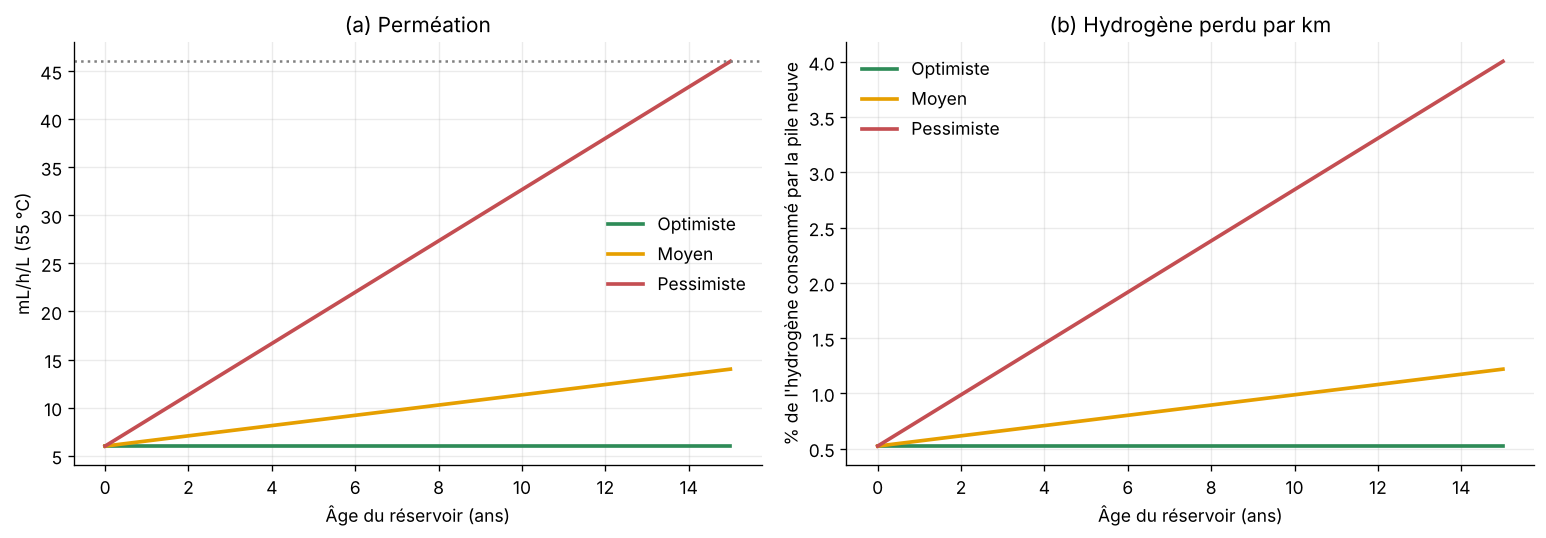

,Perméation à 15 ans (mL/h/L),Perte à 15 ans (g/jour),Perte moyenne sur 15 ans (g/km),Perte moyenne (% de m_FC neuf)
Optimiste,6.000,1.840,0.050,0.522
Moyen,13.999,4.294,0.084,0.871
Pessimiste,45.997,14.109,0.218,2.264


In [7]:
V_RES=142.2;RHO_N=8.988e-8;KM_AN=200000./15.;L_RES=15.   # L ; kg/NmL ; km/an ; ans
RES_SCEN={"Optimiste":(6.,6.),"Moyen":(6.,14.),"Pessimiste":(6.,46.)}
def perm_P(t,sc):
 P0,P1=RES_SCEN[sc] if isinstance(sc,str) else sc;t=np.asarray(t,float);tt=np.mod(t,L_RES);tt=np.where((tt==0)&(t>0),L_RES,tt)   # fin de certification incluse
 return P0+(P1-P0)*tt/L_RES
def perm_km(t,sc):return perm_P(t,sc)*V_RES*RHO_N*8760./KM_AN   # kg H2/km
M0=FC_H2EXP0/DIST
t=np.linspace(0,15,151);fig,axs=plt.subplots(1,2,figsize=(13,4.6))
for sc,c in zip(RES_SCEN,["#2E8B57","#E69F00","#C44E52"]):
 axs[0].plot(t,perm_P(t,sc),color=c,lw=2.2,label=sc);axs[1].plot(t,100*perm_km(t,sc)/M0,color=c,lw=2.2,label=sc)
axs[0].axhline(46,color="grey",ls=":");axs[0].set(xlabel="Âge du réservoir (ans)",ylabel="mL/h/L (55 °C)",title="(a) Perméation");axs[0].legend(frameon=False)
axs[1].set(xlabel="Âge du réservoir (ans)",ylabel="% de l'hydrogène consommé par la pile neuve",title="(b) Hydrogène perdu par km");axs[1].legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/"FAB_01_reservoir.png",dpi=220);plt.show()
res_tab=pd.DataFrame({sc:{"Perméation à 15 ans (mL/h/L)":perm_P(14.999,sc),"Perte à 15 ans (g/jour)":1000*perm_P(14.999,sc)*V_RES*RHO_N*24,
 "Perte moyenne sur 15 ans (g/km)":1000*trapz(perm_km(t,sc),t)/15,"Perte moyenne (% de m_FC neuf)":100*trapz(perm_km(t,sc),t)/15/M0} for sc in RES_SCEN}).T
display(res_tab.round(3))


In [8]:
P_NOM_WE=1250.          # kW : puissance nominale du stack Nel MC250 (NLR, 1,25 MW)
S_WE=1.0                # V14 : l'inventaire (activité peml) est déjà celui du stack de 1,25 MW ; ancien facteur P_NOM_WE/1000     # échelle de l'inventaire (établi pour 1 MW) = puissance nominale / 1 MW
L_VEH=15.;HWE_AN=6000.
_cache={}
def pile_tab(pf,n=61):
 k=("FC",tuple(sorted(pf.items())),n)
 if k not in _cache:
  Tf=fc_eol(pf);a=np.linspace(0,Tf,n);_cache[k]=(Tf,a,np.array([fc_state(x,pf)["H2"] for x in a])/DIST)
 return _cache[k]
def we_tab(pw,n=801):
 k=("WE",tuple(sorted(pw.items())),n)
 if k not in _cache:
  Tw=we_eol(pw);b=np.linspace(0,Tw,n);q=we_state(b,pw)
  _cache[k]=(Tw,b,np.asarray(q["SEC"],float),trapz(np.asarray(q["H2"],float),b)/4.0)   # kg H2 net produits sur la vie
 return _cache[k]
FEv=FE.reindex(IND).to_numpy();EAUv=EAU.reindex(IND).to_numpy();C3v=COMP3.reindex(IND).to_numpy()
def ikg_vec(sec,loss=0,comp=E_COMP,cf=1):return (np.asarray(sec)[:,None]*FEv*cf+EAUv+C3v*comp/3)/(1-loss)
def we_h2_horizon(pw,heures):
 """Hydrogène produit par l'électrolyseur sur l'horizon (kg), stacks successifs repartant de l'état initial."""
 Tw,b,sectab,H2vie=we_tab(pw);nfull=int(heures//Tw);rem=heures-nfull*Tw
 if rem<=0:return nfull*H2vie
 x=np.linspace(0,rem,401);return nfull*H2vie+trapz(np.asarray(we_state(x,pw)["H2"],float),x)/4.0
def vie_vehicule(pf=FC_CENTRAL,pw=WE_CENTRAL,res="Moyen",hwe=HWE_AN,decal=0.,L=L_VEH,s_we=S_WE,discret=True,loss=0,comp=E_COMP,cf=1,npa=80):
 Tf,a,mtab=pile_tab(pf);Tw,b,sectab,H2vie=we_tab(pw)
 t=np.linspace(0,L,int(L*npa)+1);afc=np.mod(t*HFC_AN,Tf);awe=np.mod((t+decal)*hwe,Tw)
 m=np.interp(afc,a,mtab);mp=perm_km(t,res);mt=m+mp;sec=np.interp(awe,b,sectab);ikg=ikg_vec(sec,loss,comp,cf)
 usage=trapz(mt[:,None]*ikg,t,axis=0)/L
 Lkm=L*KM_AN;km_stack=Tf/HFC_AN*KM_AN
 nfc=np.ceil(Lkm/km_stack-1e-9) if discret else Lkm/km_stack   # nombre entier de stacks par défaut (stacks réellement fabriqués)
 nres=np.ceil(L/L_RES-1e-9);mbar=trapz(mt,t)/L
 heures_we=L*hwe;nwe=np.ceil(heures_we/Tw-1e-9) if discret else heures_we/Tw;H2hor=we_h2_horizon(pw,heures_we)
 parts={"Usage":usage,
  "Stacks de pile":nfc*F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":nres*F_RES.to_numpy()/Lkm,
  "Stacks d'électrolyseur":mbar/(1-loss)*s_we*nwe*F_STACK_WE.to_numpy()/H2hor}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"t":t,"m":m,"mp":mp,"sec":sec,"ikm":mt[:,None]*ikg,"parts":parts,"total":sum(parts.values()),"n_FC":nfc,"km_stack":km_stack,
         "T_FC":Tf,"T_WE":Tw,"H2vie_WE":H2vie,"rempl_WE":int(((L+decal)*hwe)//Tw),"n_WE":nwe,"n_res":nres}
def reference(res="Moyen",hwe=HWE_AN,L=L_VEH,s_we=S_WE,loss=0,comp=E_COMP,cf=1):
 t=np.linspace(0,L,int(L*80)+1);mp=perm_km(t,(RES_SCEN[res][0],)*2);mt=M0+mp;ikg=ikg_vec([WE_SEC0],loss,comp,cf)[0]
 Lkm=L*KM_AN;mbar=trapz(mt,t)/L;H2ref=WE_H20/4.0*hwe*L
 parts={"Usage":mbar*ikg,"Stacks de pile":F_STACK_FC.to_numpy()/Lkm,
  "Réservoir":np.ceil(L/L_RES-1e-9)*F_RES.to_numpy()/Lkm,"Stacks d'électrolyseur":mbar/(1-loss)*s_we*F_STACK_WE.to_numpy()/H2ref}
 parts={k:pd.Series(v,index=IND) for k,v in parts.items()}
 return {"parts":parts,"total":sum(parts.values())}
V=vie_vehicule();REF=reference()
dec=pd.DataFrame({"Avec vieillissement":{k:1000*v[GWP] for k,v in V["parts"].items()},"Sans vieillissement":{k:1000*v[GWP] for k,v in REF["parts"].items()}})
dec.loc["Total"]=dec.sum();dec["Écart (g/km)"]=dec.iloc[:,0]-dec.iloc[:,1]
print(f"Vie du véhicule {L_VEH:.0f} ans = {L_VEH*KM_AN:,.0f} km ; stack de pile : {V['km_stack']:,.0f} km -> {V['n_FC']:.2f} stacks ; électrolyseur : {V['rempl_WE']} remplacement(s) ; H2 produit par stack d'électrolyseur : {V['H2vie_WE']:,.0f} kg")
print("Changement climatique (g CO2-éq/km)");display(dec.round(3))
print(f"Total : {1000*V['total'][GWP]:.2f} g/km avec vieillissement contre {1000*REF['total'][GWP]:.2f} sans (+{100*(V['total'][GWP]/REF['total'][GWP]-1):.1f} %) ; fabrication = {100*(1-V['parts']['Usage'][GWP]/V['total'][GWP]):.0f} % du total")


Vie du véhicule 15 ans = 200,000 km ; stack de pile : 137,831 km -> 2.00 stacks ; électrolyseur : 1 remplacement(s) ; H2 produit par stack d'électrolyseur : 613,632 kg
Changement climatique (g CO2-éq/km)


,Avec vieillissement,Sans vieillissement,Écart (g/km)
Usage,49.069,43.649,5.419
Stacks de pile,36.983,18.492,18.492
Réservoir,11.660,11.660,0.000
Stacks d'électrolyseur,0.682,0.322,0.360
Total,98.394,74.123,24.271


Total : 98.39 g/km avec vieillissement contre 74.12 sans (+32.7 %) ; fabrication = 50 % du total


## 1. Facteurs de normalisation et de pondération

| Catégorie EF 3.1 | Indicateur du notebook | Unité | NF (/personne) | WF (%) |
|---|---|---|---:|---:|
| Acidification | Acidification | mol H⁺ éq | 55,6 | 6,20 |
| Changement climatique | Changement climatique | kg CO₂ éq | 7 550 | 21,06 |
| Écotoxicité de l'eau douce | Écotoxicité totale | CTUe | 56 700 | 1,92 |
| Particules fines | Particules | incidence de maladie | 5,95×10⁻⁴ | 8,96 |
| Eutrophisation eau douce | Eutrophisation eau douce | kg P éq | 1,61 | 2,80 |
| Eutrophisation marine | Eutrophisation marine | kg N éq | 19,5 | 2,96 |
| Eutrophisation terrestre | Eutrophisation terrestre | mol N éq | 177 | 3,71 |
| Toxicité humaine cancérigène | Toxicité humaine totale | CTUh | 1,73×10⁻⁵ | 2,13 |
| Appauvrissement de la couche d'ozone | Ozone | kg CFC-11 éq | 0,0523 | 6,31 |
| Ressources énergétiques non renouvelables | Énergie fossile | MJ | 65 000 | 8,32 |
| Ressources minérales | Ressources minérales | kg Sb éq | 0,0636 | 7,55 |
| Ressources en eau | Utilisation de l'eau | m³ monde éq | 11 500 | 8,51 |
| Toxicité humaine non cancérigène | *fabrication seulement* | CTUh | 1,29×10⁻⁴ | 1,84 |
| Radiations ionisantes | *fabrication seulement* | kBq U235 éq | 4 220 | 5,01 |
| Usage des terres | *fabrication seulement* | pt | 819 000 | 7,94 |
| Formation photochimique d'ozone | *fabrication seulement* | kg NMVOC éq | 40,9 | 4,78 |


In [9]:
EF=pd.DataFrame([
 ("Acidification","Acidification","mol H+ éq",55.6,6.20),
 ("Changement climatique","Changement climatique","kg CO2 éq",7550.,21.06),
 ("Écotoxicité totale","Écotoxicité eau douce","CTUe",56700.,1.92),
 ("Particules","Particules fines","incidence",5.95e-4,8.96),
 ("Eutrophisation eau douce","Eutrophisation eau douce","kg P éq",1.61,2.80),
 ("Eutrophisation marine","Eutrophisation marine","kg N éq",19.5,2.96),
 ("Eutrophisation terrestre","Eutrophisation terrestre","mol N éq",177.,3.71),
 ("Toxicité humaine totale","Toxicité humaine cancérigène","CTUh",1.73e-5,2.13),
 ("Ozone","Couche d'ozone","kg CFC-11 éq",0.0523,6.31),
 ("Énergie fossile","Ressources énergétiques","MJ",65000.,8.32),
 ("Ressources minérales","Ressources minérales","kg Sb éq",0.0636,7.55),
 ("Utilisation de l'eau","Ressources en eau","m3 monde éq",11500.,8.51),
 ("Usage des terres","Usage des terres","pt",819000.,7.94),("Radiations ionisantes","Radiations ionisantes","kBq U235 éq",4220.,5.01),
 ("Formation photochimique d'ozone","Formation photochimique d'ozone","kg NMVOC éq",40.9,4.78),("Toxicité humaine non cancérigène","Toxicité humaine non cancérigène","CTUh",1.29e-4,1.84)],
 columns=["Indicateur","Catégorie EF","Unité","NF","WF_pct"]).set_index("Indicateur")
MANQUANTES={}   # V11 : les 16 catégories sont couvertes (inventaire de l'eau complet)
EF4=pd.DataFrame([("Toxicité humaine non cancérigène","CTUh",1.29e-4,1.84),("Radiations ionisantes","kBq U235 éq",4220.,5.01),
 ("Usage des terres","pt",819000.,7.94),("Formation photochimique d'ozone","kg NMVOC éq",40.9,4.78)],columns=["Catégorie EF","Unité","NF","WF_pct"]).set_index("Catégorie EF")
EF16=EF.set_index("Catégorie EF")[["Unité","NF","WF_pct"]];assert abs(EF16.WF_pct.sum()-100)<1e-9
# Fabrication sur les 16 catégories (Brightway, ecoinvent 3.11 cut-off) : fichiers pile.xlsx, peml.xlsx, reservoir.xlsx
FAB16=pd.DataFrame({"Stack de pile (128 kW)": {"Acidification": 260.1519538833514, "Changement climatique": 7433.43743851008, "Écotoxicité eau douce": 69567.60160354408, "Ressources énergétiques": 75698.40567294328, "Eutrophisation eau douce": 4.78053595844442, "Eutrophisation marine": 18.97491309036641, "Eutrophisation terrestre": 267.7069368698439, "Toxicité humaine cancérigène": 2.824620617295487e-06, "Toxicité humaine non cancérigène": 7.223935284394861e-05, "Radiations ionisantes": 329.9390378455433, "Usage des terres": 31383.32238881429, "Ressources minérales": 0.2209245325401167, "Couche d'ozone": 0.0305485554869168, "Particules fines": 0.000694520160191913, "Formation photochimique d'ozone": 70.77345779757499, "Ressources en eau": 1695.055810718058}, "Stack d'électrolyseur (1 MW)": {"Acidification": 3525.037161324252, "Changement climatique": 76481.90785513633, "Écotoxicité eau douce": 938255.3251941013, "Ressources énergétiques": 957636.8609624219, "Eutrophisation eau douce": 67.72206898190822, "Eutrophisation marine": 258.3627754221697, "Eutrophisation terrestre": 3643.123055020206, "Toxicité humaine cancérigène": 4.796978261616523e-05, "Toxicité humaine non cancérigène": 0.0008159193948438355, "Radiations ionisantes": 3610.801062275642, "Usage des terres": 494875.3762569571, "Ressources minérales": 2.259033694745131, "Couche d'ozone": 0.07114769429467616, "Particules fines": 0.01078867136866144, "Formation photochimique d'ozone": 974.5793625919089, "Ressources en eau": 14893.26611047897}, "Réservoir": {"Acidification": 11.68682895027511, "Changement climatique": 2075.004780841748, "Écotoxicité eau douce": 10675.81443876609, "Ressources énergétiques": 28566.34013265822, "Eutrophisation eau douce": 0.7259791193127696, "Eutrophisation marine": 2.336832635294235, "Eutrophisation terrestre": 21.20158628390095, "Toxicité humaine cancérigène": 5.32054990554701e-07, "Toxicité humaine non cancérigène": 1.603258346830262e-05, "Radiations ionisantes": 161.8019953358707, "Usage des terres": 7520.780972642723, "Ressources minérales": 0.00891014103732108, "Couche d'ozone": 2.336157474084723e-05, "Particules fines": 0.0001547371907187039, "Formation photochimique d'ozone": 6.665922006670208, "Ressources en eau": 449.7196840839306}}).reindex(EF16.index)
# V5 : stack de pile = inventaire de Mori et al. (2023) mis à l'échelle de 128 kW ; stack d'électrolyseur = inventaire de Lundberg (2019), 1 MW
FAB16["Stack de pile (128 kW)"]=pd.Series({"Acidification": 248.6582735672424, "Changement climatique": 3698.346742156322, "Écotoxicité eau douce": 67995.96210221738, "Ressources énergétiques": 64984.53610733856, "Eutrophisation eau douce": 4.27016797780295, "Eutrophisation marine": 17.16909518528825, "Eutrophisation terrestre": 248.604010366358, "Toxicité humaine cancérigène": 1.38979620550576e-06, "Toxicité humaine non cancérigène": 6.484218704562489e-05, "Radiations ionisantes": 843.8269015738455, "Usage des terres": 28190.78931979666, "Ressources minérales": 0.1838955299372942, "Couche d'ozone": 0.00169092666370126, "Particules fines": 0.0005863685653156342, "Formation photochimique d'ozone": 64.3280624097413, "Ressources en eau": 962.4103658170666}).reindex(EF16.index)
FAB16["Stack d'électrolyseur (1 MW)"]=pd.Series({"Acidification": 541.9303241901652, "Changement climatique": 39509.356138025, "Écotoxicité eau douce": 202177.3298567108, "Ressources énergétiques": 516877.16421177, "Eutrophisation eau douce": 22.06169155923207, "Eutrophisation marine": 57.84338021425834, "Eutrophisation terrestre": 694.5467872386303, "Toxicité humaine cancérigène": 4.108245023556852e-05, "Toxicité humaine non cancérigène": 0.0003593609038317293, "Radiations ionisantes": 6417.527789075928, "Usage des terres": 190158.3583246214, "Ressources minérales": 0.4318232282350359, "Couche d'ozone": 0.07093678234215871, "Particules fines": 0.004230264548149397, "Formation photochimique d'ozone": 217.500524451658, "Ressources en eau": 8454.03905835908}).reindex(EF16.index)
FAB16["Réservoir"]=pd.Series({"Acidification": 12.84867086932092, "Changement climatique": 2332.026270158021, "Écotoxicité eau douce": 11178.11535018604, "Ressources énergétiques": 32049.23050780235, "Eutrophisation eau douce": 0.8354225138274014, "Eutrophisation marine": 2.582498258236369, "Eutrophisation terrestre": 23.66687466869964, "Toxicité humaine cancérigène": 5.593504833465078e-07, "Toxicité humaine non cancérigène": 1.729651533295304e-05, "Radiations ionisantes": 193.9538005168125, "Usage des terres": 7952.628710906571, "Ressources minérales": 0.00902534451608675, "Couche d'ozone": 2.573331900733087e-05, "Particules fines": 0.0001653445622898199, "Formation photochimique d'ozone": 7.416588486848695, "Ressources en eau": 508.0363394698326}).reindex(EF16.index)
def score16(s,mode="complet"):
 w=EF16.WF_pct/100. if mode=="complet" else pd.Series(1/16,index=EF16.index)
 return float((s.reindex(EF16.index)/EF16.NF*w).sum())
def fab16_part(part,F12,F16s):
 # partie de fabrication par km sur 16 catégories : même répartition que sur le changement climatique
 return F16s*(part[GWP]/F12[GWP])
CATS=list(EF.index);LAB=EF["Catégorie EF"].to_dict()
WF_PRESENT=EF.WF_pct.sum()
print(f"Poids couverts : {WF_PRESENT:.2f} % ; manquants : {sum(MANQUANTES.values()):.2f} % ; total {WF_PRESENT+sum(MANQUANTES.values()):.2f} %")
def normaliser(s):
 s=pd.Series(s,index=IND) if not isinstance(s,pd.Series) else s
 return (s.reindex(CATS)/EF.NF).rename(index=LAB)                # personne-équivalent
def ponderer(s,mode="partiel"):
 w=EF.WF_pct/100. if mode=="partiel" else (EF.WF_pct/WF_PRESENT if mode=="renormalise" else pd.Series(1/len(CATS),index=CATS))
 return normaliser(s)*w.rename(index=LAB)                        # Pt
def score(s,mode="partiel"):return float(ponderer(s,mode).sum())
UPT=1e6   # µPt
display(EF)


Poids couverts : 100.00 % ; manquants : 0.00 % ; total 100.00 %


,Catégorie EF,Unité,NF,WF_pct
Indicateur,,,,
Acidification,Acidification,mol H+ éq,55.600000,6.20
Changement climatique,Changement climatique,kg CO2 éq,7550.000000,21.06
Écotoxicité totale,Écotoxicité eau douce,CTUe,56700.000000,1.92
Particules,Particules fines,incidence,0.000595,8.96
Eutrophisation eau douce,Eutrophisation eau douce,kg P éq,1.610000,2.80
Eutrophisation marine,Eutrophisation marine,kg N éq,19.500000,2.96
Eutrophisation terrestre,Eutrophisation terrestre,mol N éq,177.000000,3.71
Toxicité humaine totale,Toxicité humaine cancérigène,CTUh,0.000017,2.13
Ozone,Couche d'ozone,kg CFC-11 éq,0.052300,6.31


## 1. Les trois cas

Les données publiées sont appliquées sans conversion. Le modèle linéaire est branché sur les fonctions du modèle par mécanismes : un jeu de paramètres qui contient la clé `mu_lin` suit le modèle linéaire ; les autres suivent le modèle par mécanismes.

In [10]:
# Données publiées
DOE_FC_STATUT_H=4100.   # h jusqu'à 10 % de perte de tension, meilleure flotte sur route (DOE Program Record 16019, 2016)
DOE_FC_OBJ_H=8000.      # h jusqu'à 10 % de perte de tension, objectif ultime (DOE Program Record 20005, 2020)
DOE_WE_STATUT=4.8e-6    # V/h par cellule, statut 2022 (DOE, Technical targets for PEM electrolysis)
DOE_WE_OBJ=2.3e-6       # V/h par cellule, objectif 2026 (idem)
U0_CELL=FC_U0/FC_N      # tension de cellule à 300 A, état de référence
MU_FC={"Optimiste":.10*U0_CELL/DOE_FC_OBJ_H,"Central":.10*U0_CELL/DOE_FC_STATUT_H}
MU_WE={"Optimiste":DOE_WE_OBJ,"Central":DOE_WE_STATUT}

# Modèle linéaire branché sur les fonctions existantes (les autres fonctions les appellent par leur nom)
_fc_vcell_meca,_fc_cross_meca,_we_state_meca=fc_vcell,fc_cross,we_state
def fc_vcell(I,t,p):
    if "mu_lin" in p: return _fc_vcell_meca(I,0,FC_CENTRAL)-p["mu_lin"]*np.asarray(t,float)
    return _fc_vcell_meca(I,t,p)
def fc_cross(t,p):
    if "mu_lin" in p: return FC_CROSS0+0*np.asarray(t,float)   # crossover constant dans le modèle linéaire
    return _fc_cross_meca(t,p)
def we_state(t,p):
    if "mu_lin" not in p: return _we_state_meca(t,p)
    t=np.asarray(t,float);dv=p["mu_lin"]*t
    vm=WE_V0+dv;en=WE_E0+dv*WE_W0;h=WE_H20+0*t
    return {"fA":1+0*t,"Rratio":1+0*t,"etaF":WE_ETAF0+0*t,"Vmean":vm,"Vref":WE_VREF0+dv,"Energy":en,"H2":h,"SEC":en/h}
_cache.clear()

CAS=["Optimiste","Central","Pessimiste"]
PILE={"Optimiste":{**FC_CENTRAL,"mu_lin":MU_FC["Optimiste"]},"Central":{**FC_CENTRAL,"mu_lin":MU_FC["Central"]},"Pessimiste":FC_SCEN["Pessimiste"]}
ELEC={"Optimiste":{**WE_CENTRAL,"mu_lin":MU_WE["Optimiste"]},"Central":{**WE_CENTRAL,"mu_lin":MU_WE["Central"]},"Pessimiste":WE_SCEN["Pessimiste"]}
RESC={"Optimiste":"Optimiste","Central":"Moyen","Pessimiste":"Pessimiste"}
display(pd.DataFrame({"Pile, µ (µV/h)":{c:(1e6*MU_FC[c] if c in MU_FC else np.nan) for c in CAS},
                      "Électrolyseur, µ (µV/h)":{c:(1e6*MU_WE[c] if c in MU_WE else np.nan) for c in CAS},
                      "Réservoir, P15 (mL/h/L)":{c:RES_SCEN[RESC[c]][1] for c in CAS}}).round(2))

,"Pile, µ (µV/h)","Électrolyseur, µ (µV/h)","Réservoir, P15 (mL/h/L)"
Optimiste,9.16,2.3,6.0
Central,17.86,4.8,14.0
Pessimiste,NaN,NaN,46.0


## 2. Fin de vie et nombre de stacks

Fin de vie : −10 % de tension à 300 A pour la pile, +10 % de tension à $j_{\mathrm{ref}}$ pour l'électrolyseur (critères du DOE). Nombre de stacks : $n=\lceil L/t_{\mathrm{EoL}}\rceil$, avec $L$ = 15 ans de fonctionnement.

In [11]:
L_FC_H=L_VEH*HFC_AN;L_WE_H=L_VEH*HWE_AN
EOL={c:{"Pile":fc_eol(PILE[c]),"Électrolyseur":we_eol(ELEC[c])} for c in CAS}
vie=pd.DataFrame({c:{"Pile : fin de vie (h)":EOL[c]["Pile"],"Pile : stacks":np.ceil(L_FC_H/EOL[c]["Pile"]-1e-9),
                     "Électrolyseur : fin de vie (h)":EOL[c]["Électrolyseur"],"Électrolyseur : stacks":np.ceil(L_WE_H/EOL[c]["Électrolyseur"]-1e-9)} for c in CAS})
print(f"Horizon : pile {L_FC_H:,.0f} h ; électrolyseur {L_WE_H:,.0f} h")
display(vie.round(0))

Horizon : pile 5,554 h ; électrolyseur 90,000 h


,Optimiste,Central,Pessimiste
Pile : fin de vie (h),8000.0,4100.0,2895.0
Pile : stacks,1.0,2.0,2.0
Électrolyseur : fin de vie (h),80870.0,38750.0,34175.0
Électrolyseur : stacks,2.0,3.0,3.0


## 3. Impact de chaque convertisseur évalué seul

**Pile (par km)** : usage = hydrogène moyen sur 15 ans × impact d'un kilogramme d'hydrogène de référence (électrolyseur neuf, eau, compression) ; fabrication = $n$ stacks / 250 005 km. Chaque nouveau stack repart de l'état de référence.

**Électrolyseur (par kg d'hydrogène)** : usage = électricité moyenne par kg sur 15 ans × impact du kWh + eau ; fabrication = $n$ stacks / hydrogène produit sur 15 ans.

In [12]:
IKG_REF=pd.Series(ikg_vec([WE_SEC0])[0],index=IND)          # impact d'un kg d'hydrogène de référence (comprimé)
def _moy_horizon(f,te,L,npt=400):
    # moyenne sur l'horizon d'une grandeur f(âge), le stack repartant de l'état initial à chaque remplacement
    g=np.linspace(0,L,npt*4+1);return float(trapz(f(np.mod(g,te)),g)/L)
def pile_seule(c,cf=1.,discret=True):
    p=PILE[c];Tf,a,mtab=pile_tab(p);r=mtab/mtab[0]
    hm=_moy_horizon(lambda x:np.interp(x,a,r),Tf,L_FC_H)
    n=np.ceil(L_FC_H/Tf-1e-9) if discret else L_FC_H/Tf
    use=M0*hm*pd.Series(ikg_vec([WE_SEC0],cf=cf)[0],index=IND);fab=n*F_STACK_FC/(L_VEH*KM_AN)
    return {"n":n,"H2_moy_pct":100*(hm-1),"use":use,"fab":fab,"tot":use+fab}
def pile_ref(cf=1.):
    use=M0*pd.Series(ikg_vec([WE_SEC0],cf=cf)[0],index=IND);fab=F_STACK_FC/(L_VEH*KM_AN);return {"use":use,"fab":fab,"tot":use+fab}
def elec_seul(c,cf=1.,discret=True):
    p=ELEC[c];Tw=we_eol(p);g=np.linspace(0,L_WE_H,20001);q=we_state(np.mod(g,Tw),p)
    Etot=trapz(np.asarray(q["Energy"],float),g)/4.;Htot=trapz(np.asarray(q["H2"],float),g)/4.;sec=Etot/Htot
    n=np.ceil(L_WE_H/Tw-1e-9) if discret else L_WE_H/Tw
    use=sec*FE.reindex(IND)*cf+EAU.reindex(IND);fab=S_WE*n*F_STACK_WE/Htot
    return {"n":n,"SEC_moy_pct":100*(sec/WE_SEC0-1),"use":use,"fab":fab,"tot":use+fab}
def elec_ref(cf=1.):
    use=WE_SEC0*FE.reindex(IND)*cf+EAU.reindex(IND);fab=S_WE*F_STACK_WE/(L_WE_H/4.*WE_H20);return {"use":use,"fab":fab,"tot":use+fab}
PS={c:pile_seule(c) for c in CAS};ES={c:elec_seul(c) for c in CAS};PR,ER=pile_ref(),elec_ref()
G=GWP
tab=pd.DataFrame({"Sans vieillissement":{"Pile usage (g/km)":1e3*PR["use"][G],"Pile fabrication (g/km)":1e3*PR["fab"][G],"Pile total (g/km)":1e3*PR["tot"][G],"Pile hausse (%)":0.,
                                         "Élec. usage (kg/kg)":ER["use"][G],"Élec. fabrication (kg/kg)":ER["fab"][G],"Élec. total (kg/kg)":ER["tot"][G],"Élec. hausse (%)":0.}}
                 |{c:{"Pile usage (g/km)":1e3*PS[c]["use"][G],"Pile fabrication (g/km)":1e3*PS[c]["fab"][G],"Pile total (g/km)":1e3*PS[c]["tot"][G],
                      "Pile hausse (%)":100*(PS[c]["tot"][G]/PR["tot"][G]-1),"Élec. usage (kg/kg)":ES[c]["use"][G],"Élec. fabrication (kg/kg)":ES[c]["fab"][G],
                      "Élec. total (kg/kg)":ES[c]["tot"][G],"Élec. hausse (%)":100*(ES[c]["tot"][G]/ER["tot"][G]-1)} for c in CAS}).T
print("Changement climatique, moyenne sur 15 ans");display(tab.round(3))
conso=pd.DataFrame({c:{"Hydrogène par km, moyenne sur 15 ans (%)":PS[c]["H2_moy_pct"],"Électricité par kg, moyenne sur 15 ans (%)":ES[c]["SEC_moy_pct"]} for c in CAS})
display(conso.round(2))

Changement climatique, moyenne sur 15 ans


,Pile usage (g/km),Pile fabrication (g/km),Pile total (g/km),Pile hausse (%),Élec. usage (kg/kg),Élec. fabrication (kg/kg),Élec. total (kg/kg),Élec. hausse (%)
Sans vieillissement,43.422,18.492,61.914,0.000,4.280,0.033,4.313,0.000
Optimiste,44.909,18.492,63.401,2.402,4.467,0.066,4.533,5.110
Central,45.235,36.983,82.218,32.794,4.466,0.100,4.565,5.860
Pessimiste,46.376,36.983,83.360,34.638,4.565,0.100,4.665,8.158


,Optimiste,Central,Pessimiste
"Hydrogène par km, moyenne sur 15 ans (%)",3.42,4.17,6.80
"Électricité par kg, moyenne sur 15 ans (%)",4.38,4.36,6.67


## 4. Chaîne complète (par km)

Fonction `vie_vehicule` de la section 0 : la pile, l'électrolyseur et le réservoir vieillissent ensemble ; l'hydrogène consommé et perdu est produit par l'électrolyseur vieillissant et comprimé.

In [13]:
REF=reference(res="Moyen")
CH={c:vie_vehicule(pf=PILE[c],pw=ELEC[c],res=RESC[c]) for c in CAS}
ch=pd.DataFrame({"Sans vieillissement":{k:1e3*v[G] for k,v in REF["parts"].items()}}|{c:{k:1e3*v[G] for k,v in CH[c]["parts"].items()} for c in CAS})
ch.loc["Total"]=ch.sum();ch.loc["Hausse (%)"]=100*(ch.loc["Total"]/ch.loc["Total","Sans vieillissement"]-1)
print("Chaîne complète, changement climatique (g CO2-éq/km)");display(ch.round(2))

Chaîne complète, changement climatique (g CO2-éq/km)


,Sans vieillissement,Optimiste,Central,Pessimiste
Usage,43.65,47.03,47.50,50.37
Stacks de pile,18.49,18.49,36.98,36.98
Réservoir,11.66,11.66,11.66,11.66
Stacks d'électrolyseur,0.32,0.67,1.01,1.05
Total,74.12,77.84,97.15,100.06
Hausse (%),0.00,5.02,31.07,34.99


## 5. Catégories EF 3.1 et score unique (cas central)

In [14]:
cats=pd.DataFrame({"Pile : part fab. (%)":100*PR["fab"]/PR["tot"],"Pile : hausse (%)":100*(PS["Central"]["tot"]/PR["tot"]-1),
                   "Élec. : part fab. (%)":100*ER["fab"]/ER["tot"],"Élec. : hausse (%)":100*(ES["Central"]["tot"]/ER["tot"]-1),
                   "Chaîne : hausse (%)":100*(CH["Central"]["total"]/REF["total"]-1)}).reindex(EF.index)
cats.index=EF["Catégorie EF"];display(cats.round(1))
su=lambda s:score(pd.Series(s,index=IND))
print("Score unique, hausse (%) : pile",round(100*(su(PS["Central"]["tot"])/su(PR["tot"])-1),1),
      "; électrolyseur",round(100*(su(ES["Central"]["tot"])/su(ER["tot"])-1),1),"; chaîne",round(100*(su(CH["Central"]["total"])/su(REF["total"])-1),1))

,Pile : part fab. (%),Pile : hausse (%),Élec. : part fab. (%),Élec. : hausse (%),Chaîne : hausse (%)
Catégorie EF,,,,,
Acidification,89.7,90.1,3.1,10.5,86.9
Changement climatique,29.9,32.8,0.8,5.9,31.1
Écotoxicité eau douce,78.5,79.4,1.8,7.7,71.6
Particules fines,54.3,56.2,1.4,7.2,51.4
Eutrophisation eau douce,77.8,78.7,3.0,10.2,69.9
Eutrophisation marine,61.2,62.8,0.9,6.1,59.6
Eutrophisation terrestre,77.3,78.2,1.6,7.5,74.2
Toxicité humaine cancérigène,35.2,37.9,2.7,9.5,38.3
Couche d'ozone,86.6,87.1,31.6,66.1,93.6


Score unique, hausse (%) : pile 26.7 ; électrolyseur 4.8 ; chaîne 29.2


## 6. Sensibilité (cas central)

Intensité carbone de l'électricité (12 et 300 g CO2-éq/kWh au lieu de 79,6) et stacks comptés au prorata de la vie utilisée.

In [15]:
FE_GWP_KWH=1e3*float(FE[G])
sens={}
for nom,cf,disc in [("Cas central",1.,True),("Électricité 12 g/kWh",12./FE_GWP_KWH,True),("Électricité 300 g/kWh",300./FE_GWP_KWH,True),("Stacks au prorata",1.,False)]:
    p_,e_=pile_seule("Central",cf,disc),elec_seul("Central",cf,disc);pr_,er_=pile_ref(cf),elec_ref(cf)
    sens[nom]={"Pile : hausse (%)":100*(p_["tot"][G]/pr_["tot"][G]-1),"Pile : stacks":p_["n"],"Électrolyseur : hausse (%)":100*(e_["tot"][G]/er_["tot"][G]-1),"Électrolyseur : stacks":e_["n"]}
display(pd.DataFrame(sens).T.round(2))

,Pile : hausse (%),Pile : stacks,Électrolyseur : hausse (%),Électrolyseur : stacks
Cas central,32.79,2.00,5.86,3.00
Électricité 12 g/kWh,70.05,2.00,13.85,3.00
Électricité 300 g/kWh,14.24,2.00,4.76,3.00
Stacks au prorata,13.52,1.35,5.34,2.32


## 6 bis. Source d'électricité de l'électrolyseur

Impacts d'un kWh calculés dans Brightway (ecoinvent 3.11, EF 3.1), un fichier par source, placés à côté de ce notebook : `medium.xlsx` (mix moyen FR), `nuc.xlsx` (nucléaire FR), `wind.xlsx` (éolien FR), `pv.xlsx` (photovoltaïque 3 kWp, toiture, CdTe, RoW). Seule l'électricité de l'électrolyseur change ; la compression reste au mix résiduel.

In [16]:
MAPX={"Acidification":"acidification |","Changement climatique":"climate change | global","Écotoxicité totale":"ecotoxicity: freshwater | comparative",
 "Écotoxicité inorganique":"ecotoxicity: freshwater, inorganics","Écotoxicité organique":"ecotoxicity: freshwater, organics","Énergie fossile":"energy resources",
 "Eutrophisation eau douce":"eutrophication: freshwater","Eutrophisation marine":"eutrophication: marine","Eutrophisation terrestre":"eutrophication: terrestrial",
 "Toxicité humaine totale":"human toxicity: carcinogenic | comparative","Toxicité humaine inorganique":"human toxicity: carcinogenic, inorganics",
 "Toxicité humaine organique":"human toxicity: carcinogenic, organics","Ressources minérales":"material resources","Ozone":"ozone depletion",
 "Utilisation de l'eau":"water use","Particules":"particulate matter","Usage des terres":"| land use |","Radiations ionisantes":"ionising radiation",
 "Formation photochimique d'ozone":"photochemical oxidant","Toxicité humaine non cancérigène":"human toxicity: non-carcinogenic | comparative"}
def kwh(fichier):
    r=pd.read_excel(fichier,header=0,index_col=0).iloc[0]
    return pd.Series({k:float(r[[c for c in r.index if isinstance(c,str) and key in c][0]]) for k,key in MAPX.items()}).reindex(IND)
FE_REF,FEv_REF=FE.copy(),FEv.copy()
SOURCES={"Mix résiduel FR":FE_REF}
for nom,f in [("Mix moyen FR","medium.xlsx"),("Nucléaire","nuc.xlsx"),("Éolien","wind.xlsx"),("Photovoltaïque","pv.xlsx")]:
    if Path(f).exists(): SOURCES[nom]=kwh(f)
    else: print("fichier absent :",f)
elec_res={}
for nom,fe in SOURCES.items():
    FE=fe;FEv=fe.reindex(IND).to_numpy()
    er=elec_ref();ec=elec_seul("Central");R0=reference(res="Moyen")
    chs={c:vie_vehicule(pf=PILE[c],pw=ELEC[c],res=RESC[c])["total"][G] for c in CAS}
    elec_res[nom]={"g CO2/kWh":1e3*fe[G],"H2 sans vieill. (kg/kg)":er["tot"][G],"H2 hausse centrale (%)":100*(ec["tot"][G]/er["tot"][G]-1),
                   "Chaîne sans vieill. (g/km)":1e3*R0["total"][G]}|{f"Chaîne hausse {c.lower()} (%)":100*(chs[c]/R0["total"][G]-1) for c in CAS}
FE,FEv=FE_REF,FEv_REF
elec_tab=pd.DataFrame(elec_res).T;display(elec_tab.round(2))
elec_tab.to_csv(OUT/"trois_cas_electricite.csv",encoding="utf-8-sig")
# contrôle avec l'article (tableau de l'effet de la source d'électricité), hausse centrale de la chaîne
ART_E={'Mix résiduel FR': 31.1, 'Mix moyen FR': 31.4, 'Nucléaire': 54.3, 'Éolien': 48.6, 'Photovoltaïque': 41.3}
for k,v in ART_E.items():
    if k in elec_tab.index: print(k,round(elec_tab.loc[k,"Chaîne hausse central (%)"],1),"article :",v,"OK" if abs(elec_tab.loc[k,"Chaîne hausse central (%)"]-v)<.3 else "ÉCART")

,g CO2/kWh,H2 sans vieill. (kg/kg),H2 hausse centrale (%),Chaîne sans vieill. (g/km),Chaîne hausse optimiste (%),Chaîne hausse central (%),Chaîne hausse pessimiste (%)
Mix résiduel FR,79.64,4.31,5.86,74.12,5.02,31.07,34.99
Mix moyen FR,77.53,4.20,5.90,73.02,4.98,31.40,35.28
Nucléaire,6.48,0.39,21.13,36.05,1.91,54.32,55.30
Éolien,16.41,0.92,11.40,41.22,2.67,48.64,50.35
Photovoltaïque,34.55,1.89,7.78,50.66,3.65,41.27,43.90


Mix résiduel FR 31.1 article : 31.1 OK
Mix moyen FR 31.4 article : 31.4 OK
Nucléaire 54.3 article : 54.3 OK
Éolien 48.6 article : 48.6 OK
Photovoltaïque 41.3 article : 41.3 OK


## 6 ter. Cas pessimiste : sensibilité aux constantes du modèle par mécanismes (±20 %)

Chaque constante est diminuée puis augmentée de 20 %, les autres restant fixes. Résultat : hausse de l'impact climatique de la pile (par km) pour les constantes de la pile, et de l'hydrogène produit (par kg) pour celles de l'électrolyseur. L'écart de 20 % est conventionnel : il sert à classer les constantes.

In [17]:
pC,wP=PILE["Pessimiste"],ELEC["Pessimiste"];X00=FC_X0
def h_pile(p):
    PILE["_t"]=p;d=pile_seule("_t");del PILE["_t"];return 100*(d["tot"][G]/PR["tot"][G]-1),d["n"]
def h_elec(p):
    ELEC["_t"]=p;d=elec_seul("_t");del ELEC["_t"];return 100*(d["tot"][G]/ER["tot"][G]-1),d["n"]
def _ix0(f):
    global FC_X0
    FC_X0=X00*f;v=h_pile({**pC,"_ix0":f});FC_X0=X00;return v
TESTS={
 "Perte de surface de platine en 1 000 h (1 − S)":("Pile",lambda f:h_pile({**pC,"S1000":1-(1-pC["S1000"])*f})),
 "Forme de la loi ω":("Pile",lambda f:h_pile({**pC,"omega":pC["omega"]*f})),
 "Croissance de la résistance r (pile)":("Pile",lambda f:h_pile({**pC,"k_R":pC["k_R"]*f})),
 "Facteur de crossover x":("Pile",lambda f:h_pile({**pC,"k_mem":np.log(np.exp(pC["k_mem"]*1000.)*f)/1000.})),
 "Crossover initial i_x,0":("Pile",_ix0),
 "Activité finale de l'anode f_A,min":("Électrolyseur",lambda f:h_elec({**wP,"fA_min":wP["fA_min"]*f})),
 "Temps de décroissance τ":("Électrolyseur",lambda f:h_elec({**wP,"k_cat":wP["k_cat"]/f})),
 "Croissance des résistances dR/dt (électrolyseur)":("Électrolyseur",lambda f:h_elec({**wP,"k_R":wP["k_R"]*f})),
 "Demi-épaisseur de la membrane t50":("Électrolyseur",lambda f:h_elec({**wP,"t50_mem":wP["t50_mem"]*f}))}
lig=[]
for k,(eq,fn) in TESTS.items():
    (m,nm_),(pl,np_)=fn(.8),fn(1.2);lig.append({"Constante":k,"Équipement":eq,"-20 % (%)":m,"stacks -20 %":nm_,"+20 % (%)":pl,"stacks +20 %":np_})
oat=pd.DataFrame(lig);display(oat.round(1));oat.to_csv(OUT/"trois_cas_sensibilite_constantes.csv",index=False,encoding="utf-8-sig")
ART_OAT={'Perte de surface de platine en 1 000 h (1 − S)': (34.4, 64.6), 'Croissance de la résistance r (pile)': (34.7, 63.8), 'Croissance des résistances dR/dt (électrolyseur)': (8.5, 9.1), 'Facteur de crossover x': (33.8, 35.5), 'Crossover initial i_x,0': (34.1, 35.2), "Activité finale de l'anode f_A,min": (8.3, 8.1), 'Demi-épaisseur de la membrane t50': (8.2, 8.1), 'Temps de décroissance τ': (8.2, 8.1), 'Forme de la loi ω': (34.7, 34.6)}
for _,r in oat.iterrows():
    m,pl=ART_OAT[r["Constante"]];ok=abs(r["-20 % (%)"]-m)<.3 and abs(r["+20 % (%)"]-pl)<.3
    print(f"{r['Constante']:50s} notebook {r['-20 % (%)']:+.1f} / {r['+20 % (%)']:+.1f}   article {m:+.1f} / {pl:+.1f}   {'OK' if ok else 'ÉCART'}")

,Constante,Équipement,-20 % (%),stacks -20 %,+20 % (%),stacks +20 %
0,Perte de surface de platine en 1 000 h (1 − S),Pile,34.4,2.0,64.6,3.0
1,Forme de la loi ω,Pile,34.7,2.0,34.6,2.0
2,Croissance de la résistance r (pile),Pile,34.7,2.0,63.9,3.0
3,Facteur de crossover x,Pile,33.8,2.0,35.5,2.0
4,"Crossover initial i_x,0",Pile,34.1,2.0,35.2,2.0
5,"Activité finale de l'anode f_A,min",Électrolyseur,8.3,3.0,8.1,3.0
6,Temps de décroissance τ,Électrolyseur,8.2,3.0,8.1,3.0
7,Croissance des résistances dR/dt (électrolyseur),Électrolyseur,8.5,3.0,9.1,4.0
8,Demi-épaisseur de la membrane t50,Électrolyseur,8.2,3.0,8.1,3.0


Perte de surface de platine en 1 000 h (1 − S)     notebook +34.4 / +64.6   article +34.3 / +64.5   OK
Forme de la loi ω                                  notebook +34.7 / +34.6   article +34.6 / +34.6   OK
Croissance de la résistance r (pile)               notebook +34.7 / +63.9   article +34.6 / +63.7   OK
Facteur de crossover x                             notebook +33.8 / +35.5   article +33.7 / +35.4   OK
Crossover initial i_x,0                            notebook +34.1 / +35.2   article +34.0 / +35.1   OK
Activité finale de l'anode f_A,min                 notebook +8.3 / +8.1   article +8.3 / +8.1   OK
Temps de décroissance τ                            notebook +8.2 / +8.1   article +8.2 / +8.1   OK
Croissance des résistances dR/dt (électrolyseur)   notebook +8.5 / +9.1   article +8.5 / +9.1   OK
Demi-épaisseur de la membrane t50                  notebook +8.2 / +8.1   article +8.2 / +8.1   OK


## 6 quater. Heures de fonctionnement de l'électrolyseur

Les heures du modèle sont des heures de fonctionnement au profil mesuré, dont la charge moyenne est CH = 710 kW / 1,25 MW = 0,568. Les heures à pleine charge publiées sont converties à production égale : heures au profil = heures à pleine charge / CH. IRENA 2020, éolien terrestre : 3 200 h (cas moyen) et 4 200 h (meilleur cas) à pleine charge, soit 5 632 et 7 392 h au profil. DOE H2A : facteur de capacité 97 %, appliqué en durée (8 497 h, proche du maximum de 8 760 h). Référence : 6 000 h. Horizon de 15 ans. Hausse de l'hydrogène produit et de la chaîne complète, changement climatique.

In [18]:
HRS=[]
CH=WE_E0/4./1250.
for hpa in [3200./CH,6000.,4200./CH,0.97*8760.]:
    L_WE_H=15*hpa;er=elec_ref();R0h=reference(res="Moyen",hwe=hpa)
    for c in CAS:
        ec=elec_seul(c);v=vie_vehicule(pf=PILE[c],pw=ELEC[c],res=RESC[c],hwe=hpa)
        HRS.append({"h/an":round(hpa),"Cas":c,"Stacks élec.":ec["n"],"H2 hausse (%)":100*(ec["tot"][G]/er["tot"][G]-1),"Chaîne hausse (%)":100*(v["total"][G]/R0h["total"][G]-1)})
L_WE_H=15*6000.
hrs=pd.DataFrame(HRS);display(hrs.round(1));hrs.to_csv(OUT/"trois_cas_heures_electrolyseur.csv",index=False,encoding="utf-8-sig")
ART_H={'5632': {'Optimiste': (5.4, 5.2, 2), 'Central': (6.1, 31.2, 3), 'Pessimiste': (8.2, 35.0, 3)}, '6000': {'Optimiste': (5.1, 5.0, 2), 'Central': (5.9, 31.1, 3), 'Pessimiste': (8.2, 35.0, 3)}, '7392': {'Optimiste': (4.6, 4.7, 2), 'Central': (5.8, 31.1, 3), 'Pessimiste': (8.7, 35.3, 4)}, '8497': {'Optimiste': (4.6, 4.7, 2), 'Central': (6.1, 31.2, 4), 'Pessimiste': (8.5, 35.2, 4)}}
for _,r in hrs.iterrows():
    a=ART_H[str(r["h/an"])][r["Cas"]];ok=abs(r["H2 hausse (%)"]-a[0])<.3 and abs(r["Chaîne hausse (%)"]-a[1])<.3 and int(r["Stacks élec."])==a[2]
    print(f"{r['h/an']:5d} h/an {r['Cas']:10s} notebook {r['H2 hausse (%)']:+.1f} / {r['Chaîne hausse (%)']:+.1f} ({int(r['Stacks élec.'])} st)   article {a[0]:+.1f} / {a[1]:+.1f} ({a[2]} st)   {'OK' if ok else 'ÉCART'}")

,h/an,Cas,Stacks élec.,H2 hausse (%),Chaîne hausse (%)
0,5632,Optimiste,2.0,5.4,5.2
1,5632,Central,3.0,6.1,31.2
2,5632,Pessimiste,3.0,8.2,35.0
3,6000,Optimiste,2.0,5.1,5.0
4,6000,Central,3.0,5.9,31.1
5,6000,Pessimiste,3.0,8.2,35.0
6,7392,Optimiste,2.0,4.6,4.7
7,7392,Central,3.0,5.8,31.1
8,7392,Pessimiste,4.0,8.7,35.3
9,8497,Optimiste,2.0,4.6,4.7


 5632 h/an Optimiste  notebook +5.4 / +5.2 (2 st)   article +5.4 / +5.2 (2 st)   OK
 5632 h/an Central    notebook +6.1 / +31.2 (3 st)   article +6.1 / +31.2 (3 st)   OK
 5632 h/an Pessimiste notebook +8.2 / +35.0 (3 st)   article +8.2 / +35.0 (3 st)   OK
 6000 h/an Optimiste  notebook +5.1 / +5.0 (2 st)   article +5.1 / +5.0 (2 st)   OK
 6000 h/an Central    notebook +5.9 / +31.1 (3 st)   article +5.9 / +31.1 (3 st)   OK
 6000 h/an Pessimiste notebook +8.2 / +35.0 (3 st)   article +8.2 / +35.0 (3 st)   OK
 7392 h/an Optimiste  notebook +4.6 / +4.7 (2 st)   article +4.6 / +4.7 (2 st)   OK
 7392 h/an Central    notebook +5.8 / +31.1 (3 st)   article +5.8 / +31.1 (3 st)   OK
 7392 h/an Pessimiste notebook +8.7 / +35.3 (4 st)   article +8.7 / +35.3 (4 st)   OK
 8497 h/an Optimiste  notebook +4.6 / +4.7 (2 st)   article +4.6 / +4.7 (2 st)   OK
 8497 h/an Central    notebook +6.1 / +31.2 (4 st)   article +6.1 / +31.2 (4 st)   OK
 8497 h/an Pessimiste notebook +8.5 / +35.2 (4 st)   article +

## 7. Évolution avec l'âge du stack

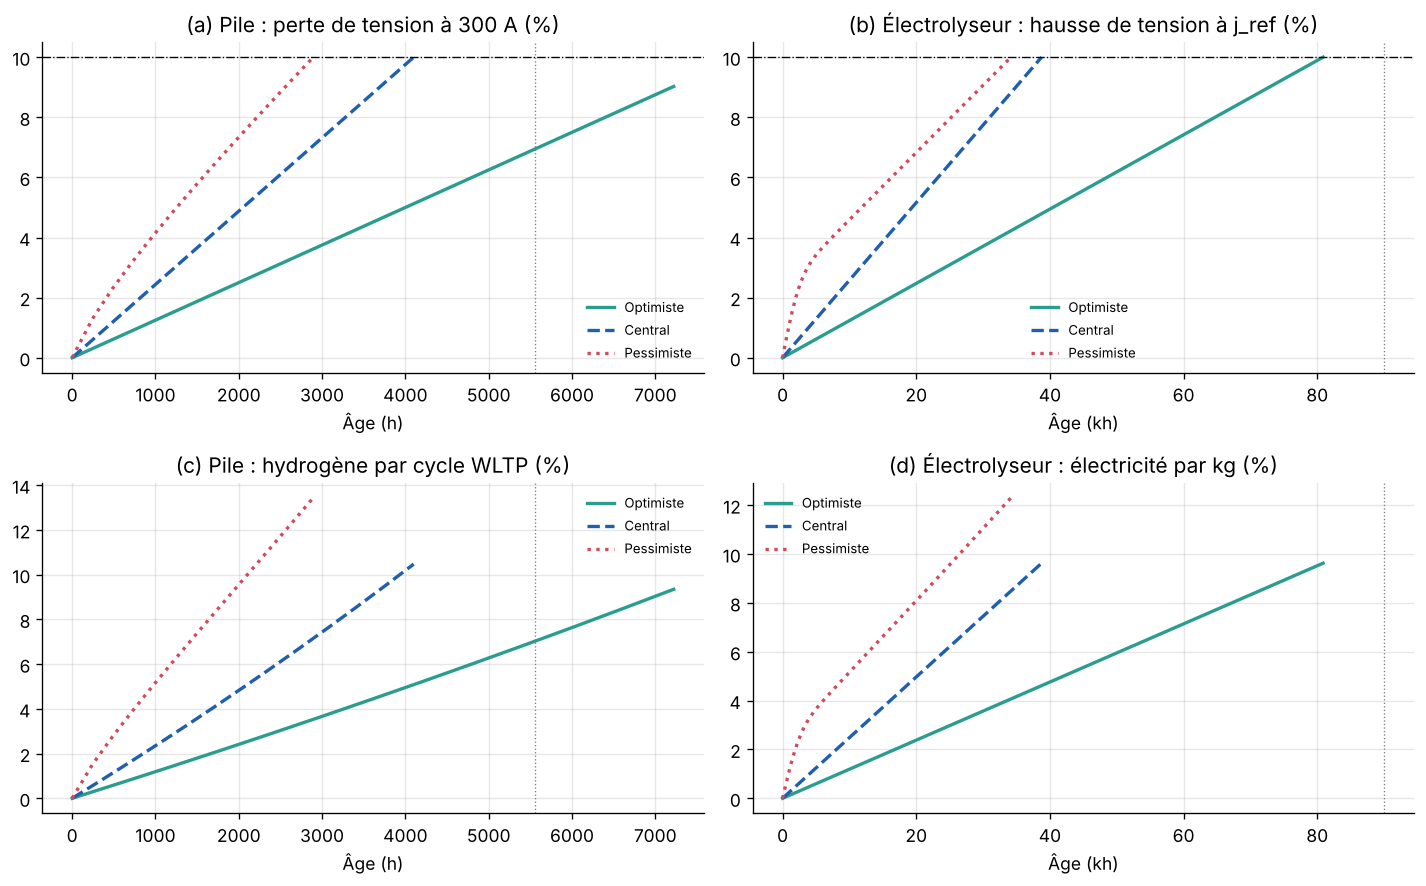

In [19]:
fig,ax=plt.subplots(2,2,figsize=(12,7.5));STY={"Optimiste":("#2a9d8f","-"),"Central":("#1f5fae","--"),"Pessimiste":("#d1495b",":")}
for c in CAS:
    col,ls=STY[c];te=min(EOL[c]["Pile"],L_FC_H*1.3);a=np.linspace(0,te,13)
    u=np.array([fc_U(FC_IREF,x,PILE[c]) for x in a]);h=np.array([fc_state(x,PILE[c])["H2"] for x in a])
    ax[0,0].plot(a,100*(1-u/FC_U0),ls=ls,color=col,lw=2,label=c);ax[1,0].plot(a,100*(h/h[0]-1),ls=ls,color=col,lw=2,label=c)
    tw=min(EOL[c]["Électrolyseur"],L_WE_H);b=np.linspace(0,tw,200);q=we_state(b,ELEC[c])
    ax[0,1].plot(b/1e3,100*(np.asarray(q["Vref"])/WE_VREF0-1),ls=ls,color=col,lw=2,label=c);ax[1,1].plot(b/1e3,100*(np.asarray(q["SEC"])/WE_SEC0-1),ls=ls,color=col,lw=2,label=c)
for a_,x_ in [(ax[0,0],L_FC_H),(ax[1,0],L_FC_H),(ax[0,1],L_WE_H/1e3),(ax[1,1],L_WE_H/1e3)]: a_.axvline(x_,color="grey",ls=":",lw=.8)
ax[0,0].axhline(10,color="k",ls="-.",lw=.8);ax[0,1].axhline(10,color="k",ls="-.",lw=.8)
ax[0,0].set(title="(a) Pile : perte de tension à 300 A (%)",xlabel="Âge (h)");ax[0,1].set(title="(b) Électrolyseur : hausse de tension à j_ref (%)",xlabel="Âge (kh)")
ax[1,0].set(title="(c) Pile : hydrogène par cycle WLTP (%)",xlabel="Âge (h)");ax[1,1].set(title="(d) Électrolyseur : électricité par kg (%)",xlabel="Âge (kh)")
for a_ in ax.flat: a_.grid(alpha=.3);a_.legend(frameon=False,fontsize=8)
fig.tight_layout();fig.savefig(OUT/"TROIS_CAS_trajectoires.png",dpi=220);plt.show()

## 8. Contrôles avec l'article et export

Les valeurs de l'article (tableaux des fins de vie, de l'impact de chaque convertisseur et de la chaîne) sont comparées aux valeurs calculées ici. Écart toléré : 1 % sur les fins de vie, 0,3 point sur les hausses.

In [20]:
ART={'fin de vie pile': {'Optimiste': 8000, 'Central': 4100, 'Pessimiste': 2895}, 'fin de vie électrolyseur': {'Optimiste': 80870, 'Central': 38750, 'Pessimiste': 34175}, 'hausse pile (%)': {'Optimiste': 2.4, 'Central': 32.8, 'Pessimiste': 34.6}, 'hausse électrolyseur (%)': {'Optimiste': 5.1, 'Central': 5.9, 'Pessimiste': 8.2}, 'hausse chaîne (%)': {'Optimiste': 5.0, 'Central': 31.1, 'Pessimiste': 35.0}}
CALC={"fin de vie pile":{c:EOL[c]["Pile"] for c in CAS},"fin de vie électrolyseur":{c:EOL[c]["Électrolyseur"] for c in CAS},
      "hausse pile (%)":{c:tab.loc[c,"Pile hausse (%)"] for c in CAS},"hausse électrolyseur (%)":{c:tab.loc[c,"Élec. hausse (%)"] for c in CAS},
      "hausse chaîne (%)":{c:ch.loc["Hausse (%)",c] for c in CAS}}
ok=True
for k in ART:
    for c in CAS:
        a,v=ART[k][c],CALC[k][c];bon=abs(v/a-1)<.01 if k.startswith("fin") else abs(v-a)<.3;ok&=bon
        print(f"{k:26s} {c:10s} notebook {v:10.1f}   article {a:8.1f}   {'OK' if bon else 'ÉCART'}")
assert ok,"écart avec l'article"
vie.to_csv(OUT/"trois_cas_fin_de_vie.csv",encoding="utf-8-sig");tab.to_csv(OUT/"trois_cas_convertisseurs.csv",encoding="utf-8-sig")
ch.to_csv(OUT/"trois_cas_chaine.csv",encoding="utf-8-sig");cats.to_csv(OUT/"trois_cas_categories.csv",encoding="utf-8-sig")
print("Exports :",sorted(p.name for p in OUT.glob("trois_cas_*")))

fin de vie pile            Optimiste  notebook     8000.0   article   8000.0   OK
fin de vie pile            Central    notebook     4100.0   article   4100.0   OK
fin de vie pile            Pessimiste notebook     2894.5   article   2895.0   OK
fin de vie électrolyseur   Optimiste  notebook    80869.8   article  80870.0   OK
fin de vie électrolyseur   Central    notebook    38750.1   article  38750.0   OK
fin de vie électrolyseur   Pessimiste notebook    34175.4   article  34175.0   OK
hausse pile (%)            Optimiste  notebook        2.4   article      2.4   OK
hausse pile (%)            Central    notebook       32.8   article     32.8   OK
hausse pile (%)            Pessimiste notebook       34.6   article     34.6   OK
hausse électrolyseur (%)   Optimiste  notebook        5.1   article      5.1   OK
hausse électrolyseur (%)   Central    notebook        5.9   article      5.9   OK
hausse électrolyseur (%)   Pessimiste notebook        8.2   article      8.2   OK
hausse chaîne (%

## 9. Limites

- Aucune vitesse n'est mesurée sur les stacks étudiés. Les cas optimiste et central reposent sur des valeurs déclarées par le DOE (statut et objectifs), et le cas pessimiste sur des cellules de laboratoire, plus sollicitées qu'un stack industriel.
- Le modèle linéaire ne voit ni la hausse du crossover de la pile ni la perte rapide d'activité de l'anode de l'électrolyseur.
- Le résultat de la pile varie par paliers avec le nombre de stacks : toute fin de vie comprise entre la moitié de l'horizon et l'horizon donne deux stacks.